**Last updated: 2026-11-23** - HFSS convergence: max delta f 0.1 -> 0.02 % (3 passes in a row), a 25 um mesh seed on every island before pass 1 (`hfss_island_mesh_um`), elements with the same target frequency in one run (TC1, TC2 in TC1-Q2-TC2) detuned 3 % in L_J so they do not hybridise, and a warning for any mode whose largest junction participation is under 0.8. HFSS uses the chain's mirror symmetry about Q2: only the south half's runs are simulated (Q0-TC0-Q1, Q1-TC1-Q2, TC0-Q1-TC1, TC1-Q2-TC2) and the north half's results are those runs relabelled (`hfss_use_mirror_symmetry`). Eigenmode runs converge on the complex frequency (HFSS's "Converge on Real Frequency Only" off), and every run reports the real frequency and Q of each mode pass by pass, warning if Q is still moving. Qubit anharmonicity target 250 -> 155 MHz so the qubit finger (0.205 um) meets the 0.200 um DFM width (Jc is fixed), E_J/E_C ~ 120-150; qubit frequencies in a V (5.05 / 4.80 / 4.55 / 4.80 / 5.05 GHz), neighbours 250 MHz apart. Substrate set to MIT LL BISQuit8: 725 um silicon, eps_r 11.45, as its own HFSS material (was HFSS library silicon, 11.9, at Metal's default 750 um); the HFSS calibrations, measured on 11.9, are rescaled by (eps_r + 1) / 2. Launchpads moved to MIT LL's 20-pin package positions (TEST04 in HIERARCHY_EXAMPLE_v3_1_1.gds, via mitll_pad.py: 6 per N/S edge, 4 per E/W, MIT LL's 160 x 200 um pad with a 100 um taper); control lines reassigned to them, qubit column moved to x = -0.1 mm to make room. Stronger qubit-coupler coupling: per-arm qubit cross (transmon_cross_arms.py) with chain arms +40 um and readout/SQUID arms -40 um, claw 40 um shorter, coupler insertion 30 -> 120 um (g ~55-73 MHz, was ~25), C_sigma tables re-measured, coupler anharmonicity target 200 -> 155 MHz (finger 0.315 um), control-line fillet 30 um. Couplers moved up and mirrored on the qubits' V (6.60 / 6.35 / 6.35 / 6.60 GHz), parked at their maximum where they cancel the direct qubit-qubit coupling: idle ZZ ~3.3-3.6 kHz per pair from a 5-mode model; coupler target anharmonicity 140 MHz (finger 0.395 um, bars 11-15 um, g 67-75 MHz).

2026-11-22: Junctions to the MIT LL SQP3.1 rules: 140 nm Dolan gap, 0.50 um taper, junction capacitance 51 fF/um^2 in C_sigma, finger widths on the 5 nm grid with L_J and the pads recomputed from them. The whole layout is turned 90 degrees into a vertical chain, so every Dolan gap lies along x; launchpads are renamed for the edge they are now on. Each SQUID lands on its metal through MIT LL's claw contacts, and a new cell checks it against the SQP3.1 rules and writes `qubits_couplers_junctions.gds`.

2026-11-20: - HFSS split into three-element runs (Q-TC-Q for each coupler, TC-Q-TC for each inner qubit), each with its control lines ending in 50 ohm. The full-array run crashed AEDT (too big) and is off. HFSS runs in AEDT 2024 R2.

# Five qubits + four tunable couplers, with their control lines

A vertical chain: Q0 at the south end of the qubit column, a tunable coupler between each pair.

**To change the design:** edit the numbers in the *Design parameters* cell, then **Restart & Run All**.

The qubits, the tunable couplers between them, and their XY and flux lines to the launchpads, without the readout. The feedline, Purcell filter and readout resonators are in `readout.ipynb`, and the whole chip (with the GDS export) is in `firstpass.ipynb`. The three notebooks each have their own copy of the parameters they share (qubit and coupler geometry, junctions, launchpads), so copy any change to those across by hand.

The only hand-placed layout coordinates are in the control-line routing table, and its comments say so. The tunable coupler is `h_coupler.py`, next to this notebook, and `capacitance.py` estimated the island capacitances that the pad sizes are computed from.

In [1]:
import importlib
import math
import os

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

from qiskit_metal import designs, draw, Dict
import qiskit_metal as qm
from qiskit_metal.qlibrary.core import QComponent
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors

# Local files next to this notebook. A running kernel can miss a file added
# after it started, so refresh the import system's view of the folder first.
importlib.invalidate_caches()
from h_coupler import TransmonHCoupler  # local file: h_coupler.py
from transmon_cross_arms import TransmonCrossArms  # local file: transmon_cross_arms.py
from mitll_pad import MitllLaunchpad, load_package_pads, pad_placement  # local file: mitll_pad.py
from capacitance import capacitance_rows, metal_geometry  # local file: capacitance.py
from squid_cell import (  # local file: squid_cell.py
    load_claw, on_grid, snap_m1, sqp_drc, squid_cell, squid_geometry, squid_origin_um,
    write_layout_gds,
)
from shapely import affinity
from shapely.geometry import box
from shapely.ops import unary_union

print("Notebook version: qubits_couplers.ipynb, last updated 2026-11-23")

Notebook version: qubits_couplers.ipynb, last updated 2026-11-23


## Design parameters

In [ ]:
# =====================================================================
#  DESIGN PARAMETERS
#  Every number you are likely to tune lives in this cell. Edit, then
#  Restart & Run All. The suffix on each name is its unit (_um / _mm).
# =====================================================================

# --- Chip ------------------------------------------------------------
chip_size_mm = 5.0  # MIT LL standard die (SQP3.1 DRM 2.9)
# Substrate: MIT LL BISQuit8 (DRM 2.1.1), 725 um high-resistivity silicon,
# eps_r 11.45 at low temperature. HFSS gets a material of its own for it:
# its library "silicon" is eps_r 11.9 (and Metal's default chip 750 um thick).
substrate_thickness_um = 725
substrate_eps_r = 11.45
substrate_material = "silicon_bisquit"
# The HFSS calibrations below were measured on HFSS's library silicon. A
# planar layout's capacitances all scale with (eps_r + 1) / 2, so they are
# rescaled to this substrate by hfss_eps_scale; set hfss_calibration_eps_r =
# substrate_eps_r once they are re-measured on it.
hfss_calibration_eps_r = 11.9
hfss_eps_scale = (substrate_eps_r + 1) / (hfss_calibration_eps_r + 1)
# M1 etch bias (DRM 2.1.3) is not compensated: every base-metal edge etches
# back 375 nm (+-30 %), which lowers C_sigma and so raises f_max, by an
# estimated ~40 MHz (qubits) and ~90 MHz (couplers). Small next to the +-15 %
# Jc spread, and flux tunes down from f_max.
cpw_width_um = 10  # default centre trace for every route
cpw_gap_um = 6

# --- Qubits (TransmonCrossArms, see transmon_cross_arms.py) -----------
# A vertical chain: Q0 at the south end, the qubits up the column and a
# coupler between each pair. Every component is at orientation 90 (turned a
# quarter turn anticlockwise), so each junction line runs along +x and the
# SQUIDs' Dolan gaps lie along x on the chip (SE.DJ.4).
n_qubits = 5
qubit_pitch_mm = 0.75
qubit_column_x_mm = -0.1  # room east of Q0/Q4's flux lines for TC0/TC3's
# Etched pocket around the cross, per arm: the length is measured from the
# edge of the central square to the arm's etched tip, the width across it.
# It is the same for every qubit. The arms along the chain (north and south on
# the chip) reach into the couplers' slots, so they are longer; the readout
# (west) and SQUID (east) arms are shorter by as much, keeping C_sigma about
# the same. The metal arm width inside the pocket is set per qubit from its
# frequency (see the junction cell); the gap and the metal arm lengths follow.
cross_etch_chain_arm_length_um = 255.45
cross_etch_side_arm_length_um = 175.45  # readout (west) and SQUID (east) arms
cross_etch_arm_width_um = 89.1

# Readout claw on the west arm: a U of metal wrapped around the arm tip.
# Sizes are of the claw metal itself. "Length" runs along the arm,
# "width" across it. The ground spacing (claw gap to cross gap) follows
# from these and the cross sizes above.
claw_outer_length_um = 170.9  # shortened with the readout arm
claw_outer_width_um = 128.9
claw_inner_length_um = 160
claw_inner_width_um = 107.1
claw_gap_um = 6

# XY drive pad (open-ended CPW). Inner qubits: placed beside the east arm,
# relative to the qubit centre. The two edge qubits are instead driven
# end-on through their outer arm (south for Q0, north for the last qubit),
# with this much ground between the arm's pocket tip and the line's open end.
edge_xy_pad_spacing_um = 30
xy_pad_dx_mm = 0.18
xy_pad_dy_mm = -0.10
xy_pad_width_um = 10
xy_pad_gap_um = 6
xy_pad_termination_gap_um = 6

# Flux-line T at the SQUID (used by every qubit and coupler)
flux_t_top_um = 15
flux_t_width_um = 5
flux_t_gap_um = 3
flux_t_inductive_gap_um = 3
flux_t_offset_um = 0

# --- Tunable couplers (TransmonHCoupler, see h_coupler.py) ------------
# One I-beam coupler midway between each qubit pair, on the qubit column.
# The tip of each neighbouring qubit's etched arm pocket sits inside one of
# its slots, with a strip of ground plane all the way round between that
# pocket and the coupler's own etch.
# How far the bars reach past each qubit pocket tip. It sets most of the
# qubit-coupler coupling: at 120 um, g ~ 75-85 MHz (3-4 fF) against a direct
# qubit-qubit 3.5 MHz, so the coupler can cancel the direct coupling at idle
# and pulse it on for fast gates. 30 um gave only ~25 MHz.
# The bar width is set per coupler from its frequency (see the junction cell).
coupler_insertion_um = 120
coupler_ground_strip_um = 5  # ground between qubit pocket and coupler etch
coupler_web_width_um = 30  # vertical web joining the bars
coupler_pocket_gap_um = 15  # coupler metal to ground plane
coupler_jj_width_um = 20

# --- Josephson junctions --------------------------------------------
# Every qubit and coupler has a symmetric SQUID: two identical Dolan-bridge
# junctions in parallel, drawn to the MIT LL SQP3.1 (BISQuit) rules. Each
# junction is a 2 um lead tapering to a finger that stops one Dolan gap short
# of the other electrode; taper + finger + gap is 2.0 um along x (SE.DJ.L).
# All qubits share one finger width and all couplers another, each snapped to
# the 5 nm grid (SE.DEV.1). Junction area = finger width x overlap.
jj_jc_ua_per_um2 = 0.5  # critical current density
jj_overlap_um = 0.20  # W_JJ: the SQP3.1 DRM gives 200 nm for a 140 nm gap
jj_dolan_gap_um = 0.140  # SE.DEV.2
jj_finger_length_um = 1.36
jj_taper_length_um = 0.50  # 2.0 um - finger - gap
jj_grid_um = 0.005  # SE.DEV.1
jj_reference_finger_width_um = 0.42  # the reference cell, for comparison
# MIT LL's claw contact (its JJconnection cell) lands each SQUID on the base
# metal: one on the island, two on the ground either side of the flux T.
jj_claw_gds = "HIERARCHY_EXAMPLE_v3_1_1.gds"
# Junction layout written by the junction-layout cell: base metal on QM1
# (5/0), junction metal on QSE1 (20/0), SE_device markers on QSE1_device (60/0)
junction_layout_gds = "qubits_couplers_junctions.gds"
# Maximum (zero-flux) frequencies; flux tunes each element down from here.
# With one junction size per element type, each frequency is set by the pad
# capacitance (C_sigma), which the junction cell sizes from these.
# Qubits in a V: Q2 lowest, Q1 = Q3, Q0 = Q4, 250 MHz steps. Every neighbouring
# pair is 250 MHz apart, past the ~140-175 MHz anharmonicity, so both
# |01>-|10> and |11>-|02> stay >= 76 MHz away, and a few % junction-area error
# (~50 MHz per 2 %) cannot swap neighbours. The equal-frequency qubits share no
# coupler.
qubit_freqs_ghz = [5.05, 4.80, 4.55, 4.80, 5.05]  # Q0..Q4
# Couplers mirror the qubits' V and park at their maximum (flux sweet spot),
# where they cancel the direct qubit-qubit coupling (3.4 MHz) against their
# own (g ~ 65-77 MHz). Picked from a 5-mode model of the chain (Q-TC-Q-TC-Q,
# 3 levels each, the measured g's): idle ZZ under 4 kHz on every pair,
# next-nearest ~0. Each sits a little above its pair's ZZ minimum (~6.5 GHz
# for Q0-Q1 / Q3-Q4, ~6.2 GHz for Q1-Q2 / Q2-Q3), so fab spread can be tuned
# down to it, and 700 MHz or more below the readout band. TC1 and TC2 are
# degenerate through Q2 (~3 MHz) at these nominal values; junction spread
# will split them by more than that. CZ: pulse the coupler to ~450-600 MHz
# above the qubits (g_eff 3-5 MHz, ~70-110 ns).
coupler_freqs_ghz = [6.60, 6.35, 6.35, 6.60]  # TC0..TC3
# The shared junction of each type is sized so the element at the middle of
# its frequency range has this anharmonicity, as HFSS + EPR will see it.
# Higher-frequency elements (smaller pads) get more.
# Jc is fixed for this run, so the qubit target sets the finger width: 155 MHz
# puts it at 0.205 um, just over the 0.200 um DFM width (SE.DJ.W.1.DFM), with
# E_J/E_C ~ 120-150 (charge dispersion under 1 Hz). Higher targets give a
# narrower finger.
qubit_target_anharmonicity_mhz = 155
# The couplers reach 120 um into the qubit pockets (strong coupling), which
# makes them heavy: even a 3 um bar is 86 fF. 140 MHz sets a finger wide
# enough for the couplers at 6.35-6.6 GHz to keep bars of ~10 um, which also
# keeps the qubit-coupler g about the same for every coupler.
coupler_target_anharmonicity_mhz = 140
# Every element must stay well inside the transmon regime
min_ej_over_ec = 50
# Tunnel-barrier capacitance per unit junction area. It adds to C_sigma, so
# it comes off each pad's share. Interpolated to Jc 0.5 uA/um^2 from the SQP3.1
# DRM's 48 fF/um^2 at Jc 0.2 and 57 fF/um^2 at Jc 1.0.
jj_specific_capacitance_ff_per_um2 = 51
# C_sigma vs pad size, from capacitance.py on this layout (2026-11-23: chain
# arms 255.45 um, side arms 175.45 um, coupler_insertion_um = 120). The
# junction cell interpolates these to size each pad. Measured with every qubit
# arm and every coupler bar at one size, the two stepped together (qubit arm /
# coupler bar: 5/3, 7.5/5, 10/7.5, 15/10, 20/15, 30/20, 45/30, 60/45 um). With
# the couplers inserted this far, each qubit-coupler pair shares 1-9 fF, so a
# coupler bar far from its paired size moves the qubit's C_sigma by a few fF
# (and vice versa): check with run_capacitance_check. After changing the
# etched pockets, claws, insertion or pitch, re-measure.
qubit_csigma_vs_arm_width_ff = {
    5: 63.9, 7.5: 73.0, 10: 80.7, 15: 91.1, 20: 100.5, 30: 121.6, 45: 153.3, 60: 192.4,
}
coupler_csigma_vs_bar_width_ff = {
    3: 86.1, 5: 96.6, 7.5: 104.7, 10: 111.4, 15: 124.3, 20: 134.8, 30: 151.0, 45: 171.1,
}
# Calibration against HFSS (project five_plus_four_hfss_5, 2026-11-09). The
# frequencies HFSS gave, at the L_J it was given, imply a C_sigma 12 % (qubits)
# and 14 % (couplers) above these tables, the same at every pad size. And EPR
# gives an anharmonicity 4 % below the plain transmon one at that C_sigma
# (the junction holds ~98 % of each mode's inductive energy, not all of it).
# Measured on library silicon, so the C_sigma factors are rescaled (see Chip).
qubit_csigma_hfss_factor = 1.12 * hfss_eps_scale
coupler_csigma_hfss_factor = 1.14 * hfss_eps_scale
anharmonicity_hfss_factor = 0.96
run_capacitance_check = True  # a minute or two

# --- Launchpads -------------------------------------------------------
# Where MIT LL's 20-pin package has them, read from its example GDS
# (mitll_pad.py): 6 SSMB pads on each of the N and S edges, 4 K-connector pads
# on each of E and W, each 160 x 200 um with its back 200 um in from the edge
# (125 um for the outer N/S pads). The taper to the CPW is not part of the
# package: 100 um here (the example's is 200 um), which leaves room for two
# lines round each end of the qubit chain.
package_gds = "HIERARCHY_EXAMPLE_v3_1_1.gds"
package_cell = "TEST04"  # the 20-pin package
pad_taper_um = 100

# --- Routing --------------------------------------------------------
control_line_fillet_um = 30  # tight enough for two lines round each end of the chain

# --- HFSS simulations -------------------------------------------------
# Run in Ansys HFSS through Metal's "hfss" renderer, which starts AEDT if it
# is not already open. Every junction is a lumped inductor at its element's
# zero-flux L_J from the junction cell, so the results are at maximum frequency.
# No readout resonators here: each qubit's claw is shorted to ground where its
# resonator would start. At the qubit frequencies the quarter-wave resonator
# (shorted at the tee) looks like ~70 ohm of inductance from the claw, against
# the claw's several kilo-ohm of capacitance, so the claw is effectively at
# ground, as in the full chip.
# The simulations are three elements at a time, each with its own control
# lines. Every inner element appears in more than one run, so the runs
# cross-check each other.
# The chain is mirror symmetric about the middle qubit: Qi and Q(n-1-i), and
# TCc and TC(n-2-c), have the same frequency, pads and junction (the frequency
# lists are palindromes). With this on, only the runs centred on the south half
# are simulated, and each north run's results are its mirror image's, relabelled:
# 4 runs instead of 7. The lists below still name the results wanted; a mirrored
# one triggers its south twin's run. The control-line routing is not an exact
# mirror image (see the routing table), so only the T1 limits differ slightly.
hfss_use_mirror_symmetry = True
# eigenmode + EPR: each coupler with the qubits on either side (Q-TC-Q)
run_hfss_coupler_epr = True
hfss_epr_couplers = list(range(n_qubits - 1))  # which couplers, e.g. [1] for just TC1
# eigenmode + EPR: each inner qubit with the couplers on either side (TC-Q-TC)
run_hfss_qubit_epr = True
hfss_epr_qubits = list(range(1, n_qubits - 1))  # inner qubits only, e.g. [2] for just Q2
# eigenmode + EPR: every qubit and coupler together, 9 modes. Too big for this
# machine: the 2026-11-18 run crashed AEDT. Leave off.
run_hfss_array_epr = False
# Render the XY and flux lines (and the XY pads) too, each ending in a
# resistor where it meets its launchpad. Each mode's Q then gives the T1
# limit from the control lines. False: no control lines, flux T's grounded.
hfss_include_control_lines = True
hfss_control_line_ohms = 50
hfss_max_passes = 60
hfss_basis_order = -1  # 0 zero, 1 first, 2 second, -1 mixed
# Eigenmode convergence, % change in frequency per pass. 0.02 % is ~1 MHz at
# 5 GHz. At 0.1 % the 2026-11-23 runs stopped while every mode was still
# climbing 2-4 MHz a pass, an estimated ~10 MHz (up to ~18) short of converged.
hfss_max_delta_f = 0.02
hfss_min_converged = 3  # passes in a row that must meet it before HFSS stops
# Mesh seed: largest mesh edge on each qubit cross, coupler island and claw
# head before the first pass. Unseeded, pass 1 came out at about half the final
# frequency and ~15 passes went on refining a mesh far too coarse to start
# from; small per-pass changes then hid how far each mode still had to go.
# None: no seed.
hfss_island_mesh_um = 25
# Mixed modes. Two elements in one run with (nearly) the same target
# frequency, e.g. TC1 and TC2 at 6.35 GHz in TC1-Q2-TC2, hybridise into
# symmetric and antisymmetric modes: each junction then holds ~half of each
# mode, and the anharmonicities and couplings EPR gives are meaningless. Within
# a run, an element whose target is within hfss_degenerate_mhz of an earlier
# element's gets its L_J raised by hfss_degenerate_lj_detune (3 % moves it
# ~1.5 %, ~100 MHz, down), and its target in that run's table moves with it.
hfss_degenerate_mhz = 50
hfss_degenerate_lj_detune = 0.03
# A warning if a mode's largest junction participation is below this: the
# mode is shared between elements and its label (and the numbers under it)
# cannot be trusted.
hfss_min_participation = 0.8
# False: HFSS converges on the complex eigenfrequency (real part and the loss
# to the 50 ohm control lines), not on the real part alone (pyEPR's default).
hfss_converge_on_real_freq = False
# The complex delta-f is dominated by the real part, so Q (the imaginary part)
# is also checked after each run: a warning if any mode's Q changed by more
# than this over the last pass.
hfss_max_delta_q_pct = 2.0
hfss_max_delta_s = 0.02  # driven-modal convergence, change in S per pass
hfss_buffer_mm = 0.3  # substrate and vacuum beyond what is rendered
hfss_project_file = "qubits_couplers_hfss.aedt"  # new each run; _2, _3... if taken
hfss_results_dir = "hfss_results/qubits_couplers"  # mode tables and chi matrices, as CSV

## Josephson junctions

In [3]:
# One junction size for all qubits and one for all couplers; each element's
# frequency then comes from its pad capacitance.
#   1. E_J: the element in the middle of the frequency list gets its type's
#      target anharmonicity.
#   2. Each element's E_C (so C_sigma) puts it at its own frequency.
#   3. Each pad is sized from the C_sigma tables in the parameters.
# C_sigma and the anharmonicity are what HFSS + EPR will see: the tables are
# scaled by the HFSS factors in the parameters, and the plain transmon
# anharmonicity is aimed above the target by anharmonicity_hfss_factor.
# Levels come from the transmon Hamiltonian 4 E_C (n - n_g)^2 - E_J cos(phi),
# solved in the charge basis. At zero flux a symmetric SQUID is one junction
# with the I_c of both halves. E_C/h = e^2 / (2 h C), E_J/h = I_c Phi_0 / (2 pi h).
import numpy as np
from scipy.optimize import brentq

EC_GHZ_FF = 19.37  # e^2 / 2h, in GHz * fF
EJ_GHZ_PER_UA = 496.7  # Phi_0 / (2 pi h), in GHz per uA
PHI0_2PI_NH_UA = 0.3291  # Phi_0 / 2 pi, in nH * uA


def transmon_levels(ej_ghz, ec_ghz, ng=0.25, n_cut=30):
    """f01 and anharmonicity f12 - f01, in GHz. n_g = 0.25 sits mid-way in
    the charge dispersion, which is negligible at these E_J/E_C."""
    n = np.arange(-n_cut, n_cut + 1)
    h = np.diag(4 * ec_ghz * (n - ng) ** 2)
    h -= ej_ghz / 2 * (np.eye(n.size, k=1) + np.eye(n.size, k=-1))
    e = np.linalg.eigvalsh(h)
    return e[1] - e[0], e[2] - 2 * e[1] + e[0]


def ec_for(ej_ghz, freq_ghz):
    return brentq(lambda ec: transmon_levels(ej_ghz, ec)[0] - freq_ghz, 1e-3, 5.0)


def snap_to_grid(x_um):
    return round(round(x_um / jj_grid_um) * jj_grid_um, 6)


def junction_set(prefix, freqs_ghz, alpha_mhz):
    """Shared SQUID for one element type, and each element's C_sigma.

    The finger width that gives the target anharmonicity is snapped to the
    5 nm grid, and E_J, L_J and every element's C_sigma (so its pad) follow
    from the snapped width, so each element still lands on its frequency.
    """
    f_mid = (min(freqs_ghz) + max(freqs_ghz)) / 2
    alpha_ghz = -alpha_mhz / anharmonicity_hfss_factor / 1e3
    ej_exact_ghz = brentq(
        lambda ej: transmon_levels(ej, ec_for(ej, f_mid))[1] - alpha_ghz, 10, 300
    )
    finger_exact_um = ej_exact_ghz / EJ_GHZ_PER_UA / 2 / jj_jc_ua_per_um2 / jj_overlap_um
    finger_um = snap_to_grid(finger_exact_um)
    assert 0.100 <= finger_um <= 10.0, (
        f"{prefix} finger {finger_um:.3f} um is outside 0.100-10.0 um (SE.DJ.W.1)"
    )
    if finger_um < 0.200:
        print(f"  WARNING: {prefix} finger {finger_um:.3f} um is under the 0.200 um "
              "DFM width (SE.DJ.W.1.DFM).")
    area_um2 = finger_um * jj_overlap_um  # each of the two junctions
    ic_ua = 2 * area_um2 * jj_jc_ua_per_um2  # whole SQUID
    ej_ghz = ic_ua * EJ_GHZ_PER_UA
    cj_ff = 2 * area_um2 * jj_specific_capacitance_ff_per_um2
    out = {}
    for i, f in enumerate(freqs_ghz):
        ec_ghz = ec_for(ej_ghz, f)
        assert ej_ghz / ec_ghz >= min_ej_over_ec, (
            f"{prefix}{i}: E_J/E_C = {ej_ghz / ec_ghz:.0f}, under min_ej_over_ec = {min_ej_over_ec}"
        )
        out[f"{prefix}{i}"] = dict(
            freq_ghz=f,
            ec_mhz=ec_ghz * 1e3,
            alpha_mhz=transmon_levels(ej_ghz, ec_ghz)[1] * 1e3 * anharmonicity_hfss_factor,
            ej_ghz=ej_ghz,
            ej_over_ec=ej_ghz / ec_ghz,
            # f01 spread between n_g = 0 and 1/2 (charge-noise sensitivity)
            dispersion_khz=abs(transmon_levels(ej_ghz, ec_ghz, ng=0.0)[0]
                               - transmon_levels(ej_ghz, ec_ghz, ng=0.5)[0]) * 1e6,
            csigma_ff=EC_GHZ_FF / ec_ghz,
            pad_csigma_ff=EC_GHZ_FF / ec_ghz - cj_ff,
            cj_ff=cj_ff,
            ic_na=ic_ua * 1e3,
            ic_exact_na=ej_exact_ghz / EJ_GHZ_PER_UA * 1e3,
            lj_nh=PHI0_2PI_NH_UA / ic_ua,
            area_um2=area_um2,
            finger_um=finger_um,
            finger_exact_um=finger_exact_um,
        )
    return out


squids = junction_set("Q", qubit_freqs_ghz, qubit_target_anharmonicity_mhz)
squids.update(junction_set("TC", coupler_freqs_ghz, coupler_target_anharmonicity_mhz))


def csigma_from_table(size, table):
    """C_sigma at a pad size, interpolated (or extrapolated) as size_from_table."""
    sizes = sorted(table)
    i = int(np.clip(np.searchsorted(sizes, size) - 1, 0, len(sizes) - 2))
    s0, s1 = sizes[i], sizes[i + 1]
    return table[s0] + (size - s0) * (table[s1] - table[s0]) / (s1 - s0)


def size_from_table(target_ff, table, name):
    """Pad size giving target_ff, by linear interpolation in the table."""
    sizes = sorted(table)
    caps = [table[s] for s in sizes]
    if not caps[0] <= target_ff <= caps[-1]:
        print(f"  WARNING: {name} needs {target_ff:.1f} fF, outside the measured "
              f"{caps[0]:.1f}-{caps[-1]:.1f} fF; its pad size is extrapolated.")
        i = 0 if target_ff < caps[0] else len(sizes) - 2
        s0, s1, c0, c1 = sizes[i], sizes[i + 1], caps[i], caps[i + 1]
        return s0 + (target_ff - c0) * (s1 - s0) / (c1 - c0)
    return float(np.interp(target_ff, caps, sizes))


# Pad sizes, from the C_sigma tables as HFSS sees them: qubits' metal arm
# width inside the fixed etched pocket, couplers' bar width.
csigma_tables = {
    "Q": {k: v * qubit_csigma_hfss_factor for k, v in qubit_csigma_vs_arm_width_ff.items()},
    "TC": {k: v * coupler_csigma_hfss_factor for k, v in coupler_csigma_vs_bar_width_ff.items()},
}
for name, s in squids.items():
    table = csigma_tables[name.rstrip("0123456789")]
    s["pad_um"] = size_from_table(s["pad_csigma_ff"], table, name)
    # Forward again from the pad and the snapped junction: what the layout gives
    s["csigma_pred_ff"] = csigma_from_table(s["pad_um"], table) + s["cj_ff"]
    f, alpha = transmon_levels(s["ej_ghz"], EC_GHZ_FF / s["csigma_pred_ff"])
    s["freq_pred_ghz"], s["alpha_pred_mhz"] = f, alpha * 1e3 * anharmonicity_hfss_factor
qubit_arm_widths_um = [squids[f"Q{i}"]["pad_um"] for i in range(n_qubits)]
coupler_bar_widths_um = [squids[f"TC{i}"]["pad_um"] for i in range(n_qubits - 1)]

print(f"Jc {jj_jc_ua_per_um2} uA/um^2, overlap {jj_overlap_um} um, Dolan gap "
      f"{jj_dolan_gap_um} um, C_j {jj_specific_capacitance_ff_per_um2} fF/um^2, "
      f"reference finger {jj_reference_finger_width_um} um")
for kind, first in (("Qubits", "Q0"), ("Couplers", "TC0")):
    s = squids[first]
    print(f"{kind}: finger {s['finger_exact_um']:.4f} um snapped to {s['finger_um']:.3f} um, "
          f"SQUID Ic {s['ic_exact_na']:.2f} -> {s['ic_na']:.2f} nA "
          f"({(s['ic_na'] / s['ic_exact_na'] - 1) * 100:+.2f} %)")
print("        finger  area/JJ  Ic/JJ   L_J    C_j    C_sigma  pad     f_max  f_pred  alpha  E_J/E_C  charge")
print("        (um)    (um^2)   (nA)   (nH)   (fF)    (fF)    (um)    (GHz)  (GHz)   (MHz)          disp. (kHz)")
for name, s in squids.items():
    print(f"  {name:<5} {s['finger_um']:5.3f}  {s['area_um2']:7.4f} {s['ic_na'] / 2:6.2f}"
          f" {s['lj_nh']:6.2f} {s['cj_ff']:6.2f}  {s['csigma_pred_ff']:7.2f} {s['pad_um']:6.2f}"
          f"   {s['freq_ghz']:5.3f}  {s['freq_pred_ghz']:6.3f} {s['alpha_pred_mhz']:6.0f}"
          f"  {s['ej_over_ec']:6.0f}   {s['dispersion_khz']:.2g}")
print("L_J: the whole SQUID at zero flux. C_j: both junctions. C_sigma, alpha: as")
print("HFSS + EPR will see them. Pad: qubit arm width, coupler bar width. Charge")
print("dispersion: f01 spread over the offset charge.")
ladder = qubit_freqs_ghz
for i in range(n_qubits - 1):
    d_mhz = abs(ladder[i + 1] - ladder[i]) * 1e3
    a_mhz = [abs(squids[f"Q{k}"]["alpha_pred_mhz"]) for k in (i, i + 1)]
    print(f"  Q{i}-Q{i + 1}: detuning {d_mhz:.0f} MHz, |11>-|02> {min(abs(d_mhz - a) for a in a_mhz):.0f} MHz away")


Jc 0.5 uA/um^2, overlap 0.2 um, Dolan gap 0.14 um, C_j 51 fF/um^2, reference finger 0.42 um
Qubits: finger 0.2064 um snapped to 0.205 um, SQUID Ic 41.29 -> 41.00 nA (-0.70 %)
Couplers: finger 0.3975 um snapped to 0.395 um, SQUID Ic 79.49 -> 79.00 nA (-0.62 %)
        finger  area/JJ  Ic/JJ   L_J    C_j    C_sigma  pad     f_max  f_pred  alpha  E_J/E_C  charge
        (um)    (um^2)   (nA)   (nH)   (fF)    (fF)    (um)    (GHz)  (GHz)   (MHz)          disp. (kHz)
  Q0    0.205   0.0410  20.50   8.03   4.18   115.66  21.25   5.050   5.050   -174     122   0.0003
  Q1    0.205   0.0410  20.50   8.03   4.18   128.49  26.87   4.800   4.800   -156     135   5.7e-05
  Q2    0.205   0.0410  20.50   8.03   4.18   143.52  33.46   4.550   4.550   -139     151   8.9e-06
  Q3    0.205   0.0410  20.50   8.03   4.18   128.49  26.87   4.800   4.800   -156     135   5.7e-05
  Q4    0.205   0.0410  20.50   8.03   4.18   115.66  21.25   5.050   5.050   -174     122   0.0003
  TC0   0.395   0.0790  39.50 

## Qubits and tunable couplers

In [4]:
design = designs.DesignPlanar()
design.chips.main.size.size_x = f"{chip_size_mm}mm"
design.chips.main.size.size_y = f"{chip_size_mm}mm"
design.chips.main.size.size_z = f"-{substrate_thickness_um}um"
design.chips.main.material = substrate_material  # made in AEDT by the HFSS cell
design.variables.cpw_width = f"{cpw_width_um}um"
design.variables.cpw_gap = f"{cpw_gap_um}um"
design.overwrite_enabled = True

flux_t_options = dict(
    t_top=f"{flux_t_top_um}um",
    t_width=f"{flux_t_width_um}um",
    t_gap=f"{flux_t_gap_um}um",
    t_inductive_gap=f"{flux_t_inductive_gap_um}um",
    t_offset=f"{flux_t_offset_um}um",
)


# The etched pocket is the same for every qubit; the metal arm inside it
# varies. Gap, and metal arm lengths (centre to tip) along the chain and to
# the side, for a given arm width:
def cross_gap_and_lengths(arm_width_um):
    gap_um = (cross_etch_arm_width_um - arm_width_um) / 2
    tip_um = cross_etch_arm_width_um / 2 - gap_um
    return gap_um, tip_um + cross_etch_chain_arm_length_um, tip_um + cross_etch_side_arm_length_um


# Centre to the etched tip of the chain arms, and of the readout and SQUID arms
chain_pocket_tip_um = cross_etch_arm_width_um / 2 + cross_etch_chain_arm_length_um
pocket_tip_um = cross_etch_arm_width_um / 2 + cross_etch_side_arm_length_um

# Claw metal thicknesses and the ground spacing, from the outer/inner sizes.
claw_side_um = (claw_outer_width_um - claw_inner_width_um) / 2
claw_back_um = claw_outer_length_um - claw_inner_length_um
claw_ground_spacing_um = (claw_inner_width_um - cross_etch_arm_width_um) / 2 - claw_gap_um
if claw_ground_spacing_um < 0:
    print(
        f"WARNING: claw inner width {claw_inner_width_um} um is too narrow for the "
        f"{cross_etch_arm_width_um} um arm pocket plus the claw gap. Ground spacing = "
        f"{claw_ground_spacing_um:.2f} um: the claw overlaps the pocket."
    )
# Distance from qubit centre to the claw finger tips, vs. the E/W arm pocket.
claw_tip_um = pocket_tip_um + claw_ground_spacing_um + claw_gap_um - claw_inner_length_um
if claw_tip_um - claw_gap_um < cross_etch_arm_width_um / 2:
    print(
        f"WARNING: claw fingers reach {claw_tip_um:.1f} um from the qubit centre and "
        f"run into the E/W arm pocket (edge at {cross_etch_arm_width_um / 2} um)."
    )


def qubit_y(i):
    """y position (mm) of qubit i, centred on the chip."""
    return (i - (n_qubits - 1) / 2) * qubit_pitch_mm


qubits, xy_pads = [], []
for i in range(n_qubits):
    y_pos = qubit_y(i)
    arm_width_um = qubit_arm_widths_um[i]
    cross_gap_um, chain_arm_um, side_arm_um = cross_gap_and_lengths(arm_width_um)
    qubits.append(
        TransmonCrossArms(
            design,
            f"Q{i}",
            options=dict(
                pos_x=f"{qubit_column_x_mm}mm",
                pos_y=f"{y_pos}mm",
                orientation="90",
                cross_width=f"{arm_width_um}um",
                cross_length=f"{side_arm_um}um",
                # At orientation 90 the component's west and east arms point
                # south and north, along the chain; its north (claw) and south
                # (SQUID) arms point west and east.
                arm_lengths=dict(west=f"{chain_arm_um}um", east=f"{chain_arm_um}um"),
                cross_gap=f"{cross_gap_um}um",
                make_fl=True,
                gds_cell_name=f"SQUID_Q{i}",  # see the GDS export cell
                fl_options=flux_t_options,
                connection_pads=dict(
                    readout=dict(
                        connector_type="0",
                        claw_length=f"{claw_inner_length_um}um",
                        claw_width=f"{claw_side_um}um",
                        claw_width_back=f"{claw_back_um}um",
                        ground_spacing=f"{claw_ground_spacing_um}um",
                        claw_gap=f"{claw_gap_um}um",
                        connector_location="90",
                    )
                ),
            ),
        )
    )
    if i in (0, n_qubits - 1):
        # Edge qubit: open end faces the outer arm tip, line leaves sideways
        side = -1 if i == 0 else 1
        reach_um = chain_pocket_tip_um + edge_xy_pad_spacing_um + xy_pad_termination_gap_um
        xy_x, xy_y = qubit_column_x_mm, y_pos + side * reach_um / 1e3
        xy_orient = "90" if i == 0 else "270"
    else:
        xy_x, xy_y = qubit_column_x_mm + xy_pad_dx_mm, y_pos + xy_pad_dy_mm
        xy_orient = "180"
    xy_pads.append(
        OpenToGround(
            design,
            f"XY_pad_{i}",
            options=dict(
                pos_x=f"{xy_x}mm",
                pos_y=f"{xy_y}mm",
                orientation=xy_orient,
                width=f"{xy_pad_width_um}um",
                gap=f"{xy_pad_gap_um}um",
                termination_gap=f"{xy_pad_termination_gap_um}um",
            ),
        )
    )

print(f"Design initialized on a {chip_size_mm} x {chip_size_mm} mm chip.")
print(f"Placed qubits Q0-Q{n_qubits - 1} and their XY coupling pads.")
print("  arm widths " + ", ".join(f"Q{i} {w:.1f}" for i, w in enumerate(qubit_arm_widths_um)) + " um")

Design initialized on a 5.0 x 5.0 mm chip.
Placed qubits Q0-Q4 and their XY coupling pads.
  arm widths Q0 21.2, Q1 26.9, Q2 33.5, Q3 26.9, Q4 21.2 um


In [5]:
# Coupler geometry follows from the qubit pockets and the coupler knobs, so
# changing the qubit pitch or etch size keeps each pocket tip centred in its
# slot with at least the ground strip around it (more in front of the tip
# when the web is narrower than the room available).
pocket_tip_from_coupler_um = (
    qubit_pitch_mm * 1e3 / 2 - chain_pocket_tip_um
)
coupler_clearance_um = coupler_ground_strip_um + coupler_pocket_gap_um
coupler_bar_length_um = 2 * (pocket_tip_from_coupler_um + coupler_insertion_um)
coupler_slot_height_um = cross_etch_arm_width_um + 2 * coupler_clearance_um
# The web's etch must leave at least the ground strip before each pocket tip
web_room_um = 2 * (pocket_tip_from_coupler_um - coupler_clearance_um)
assert coupler_web_width_um <= web_room_um, (
    f"coupler_web_width_um = {coupler_web_width_um} um does not fit between the "
    f"neighbouring qubit pockets (room for {web_room_um:.0f} um): narrow the web, "
    "reduce coupler_ground_strip_um / coupler_pocket_gap_um, or widen qubit_pitch_mm."
)

tunable_couplers = []
for i in range(n_qubits - 1):
    tunable_couplers.append(
        TransmonHCoupler(
            design,
            f"TC{i}",
            options=dict(
                pos_x=f"{qubit_column_x_mm}mm",
                pos_y=f"{(qubit_y(i) + qubit_y(i + 1)) / 2}mm",
                orientation="90",
                bar_length=f"{coupler_bar_length_um}um",
                bar_width=f"{coupler_bar_widths_um[i]}um",
                slot_height=f"{coupler_slot_height_um}um",
                web_width=f"{coupler_web_width_um}um",
                pocket_gap=f"{coupler_pocket_gap_um}um",
                jj_width=f"{coupler_jj_width_um}um",
                make_fl=True,
                gds_cell_name=f"SQUID_TC{i}",  # see the GDS export cell
                fl_options=flux_t_options,
            ),
        )
    )

print(f"Placed tunable couplers TC0-TC{n_qubits - 2} between the qubits.")
print(
    f"  coupler bars {coupler_bar_length_um:.0f} um long, web "
    f"{coupler_web_width_um:.0f} um, slot {coupler_slot_height_um:.0f} um tall"
)
print("  bar widths " + ", ".join(f"TC{i} {w:.1f}" for i, w in enumerate(coupler_bar_widths_um)) + " um")

Placed tunable couplers TC0-TC3 between the qubits.
  coupler bars 390 um long, web 30 um, slot 129 um tall
  bar widths TC0 11.0, TC1 14.9, TC2 14.9, TC3 11.0 um


## Launchpads and control lines

In [6]:
# Wirebond launchpads at the 20-pin package's positions (see the parameters).
# Numbered west->east (N/S edges), south->north (E/W).
for edge, pads in load_package_pads(package_gds, package_cell).items():
    for n, (along_um, back_um) in enumerate(pads, start=1):
        MitllLaunchpad(
            design,
            f"LP_{edge}{n}",
            options=pad_placement(
                edge, along_um, back_um, chip_size_mm, taper_height=f"{pad_taper_um}um"
            ),
        )

print("Placed launchpads.")

Placed launchpads.


In [7]:
# Control lines: the edge qubits' XY lines leave along the column from the
# outer arms (Q0 to S2, Q4 to N2). Every other line leaves the qubit column
# heading east, and the launchpads are assigned in perimeter order
# (S2 -> S6 -> E1..E4 -> N6..N2) to keep the routes nested and crossing-free:
# Q0's and Q4's flux lines pass outside their XY lines to S3 and N3. S1 and
# N1 are unused, W1 is the readout input (firstpass.ipynb) and W2-W4 are
# unused.
#
# Each east-going line runs from its start pin out to x = `reach`, then:
#   - to an E/W pad: runs along to the pad's y and into it
#   - to a N/S pad: runs out to y = `row`, then across to the pad's x.
#     With row=None it runs straight out at the pad's own x (reach unused).
# A line leaving along the column runs out to `row`, then across to the pad's
# x (N/S pad), or across to `reach` and along into the pad (E/W pad). Lines
# that turn off sooner get the inner rows. Coordinates in mm.
control_lines = [
    # (name,                  start,      pin,         pad,     reach, row)
    ("XY_line_0",             "XY_pad_0", "open",      "LP_S2", None,  -1.88),
    ("Flux_line_0",           "Q0",       "flux_line", "LP_S3", 0.27,  -1.935),
    ("Coupler_flux_line_0",   "TC0",      "flux_line", "LP_S4", None,  None),
    ("XY_line_1",             "XY_pad_1", "open",      "LP_S5", None,  None),
    ("Flux_line_1",           "Q1",       "flux_line", "LP_S6", 1.55,  -1.92),
    ("Coupler_flux_line_1",   "TC1",      "flux_line", "LP_E1", 1.70,  None),
    ("XY_line_2",             "XY_pad_2", "open",      "LP_E2", 1.85,  None),
    ("Flux_line_2",           "Q2",       "flux_line", "LP_E3", 1.85,  None),
    ("Coupler_flux_line_2",   "TC2",      "flux_line", "LP_E4", 1.70,  None),
    ("XY_line_3",             "XY_pad_3", "open",      "LP_N6", 1.55,  1.92),
    ("Flux_line_3",           "Q3",       "flux_line", "LP_N5", None,  None),
    ("Coupler_flux_line_3",   "TC3",      "flux_line", "LP_N4", None,  None),
    ("Flux_line_4",           "Q4",       "flux_line", "LP_N3", 0.27,  1.935),
    ("XY_line_4",             "XY_pad_4", "open",      "LP_N2", None,  1.88),
]


def control_corners(start, pin, pad, reach, row):
    """Corner points for one control line, from the pin and pad positions."""
    start_pin = design.components[start].pins[pin]
    x0, y0 = start_pin.middle
    px, py = design.components[pad].pins["tie"].middle
    if abs(start_pin.normal[1]) > abs(start_pin.normal[0]):  # leaves along the column
        if pad[3] in "EW":
            return [(x0, row), (reach, row), (reach, py)]
        return [(x0, row), (px, row)]
    if pad[3] in "EW":
        return [(reach, y0)] + ([(reach, py)] if abs(py - y0) > 1e-6 else [])
    if row is None:
        return [(px, y0)]
    return [(reach, y0), (reach, row), (px, row)]


for name, start, pin, pad, reach, row in control_lines:
    RouteAnchors(
        design,
        name,
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=start, pin=pin),
                end_pin=dict(component=pad, pin="tie"),
            ),
            anchors=Dict(dict(enumerate(control_corners(start, pin, pad, reach, row)))),
            fillet=f"{control_line_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )

print("XY drive and flux lines routed to launchpads.")

XY drive and flux lines routed to launchpads.


## Junction layout and design-rule check

Each element's SQUID, drawn to the MIT LL SQP3.1 rules by `squid_cell.py` and placed unrotated on its junction line, so every Dolan gap lies along x with the finger to its left. The island lands on its metal through one of MIT LL's claw contacts (from `jj_claw_gds`), the ground through two, one each side of the flux T. The cell checks every SQUID against the rules, with the base metal around it, and writes `junction_layout_gds`: base metal on QM1, junction metal on QSE1, SE_device markers, and the chip edge.

In [8]:
# Each claw needs base metal 0.2 um past its SE all round (SE.MET.O.4). On the
# island that is a small head of metal at the junction end of the arm or bar,
# added to the design here so the capacitance check and HFSS see it. Each
# claw also needs a keyhole in the base metal under it; the SE covers the
# keyhole, so it is cut only in the GDS.
class ClawHead(QComponent):
    """Base metal round a SQUID's island claw: a rectangle, options.rect_um
    = "x0 y0 x1 y1" in um."""

    default_options = Dict(rect_um="0 0 0 0")
    component_metadata = Dict(short_name="claw", _qgeometry_table_poly="True")

    def make(self):
        x0, y0, x1, y1 = (float(t) / 1e3 for t in self.options.rect_um.split())
        head = draw.rectangle(x1 - x0, y1 - y0, (x0 + x1) / 2, (y0 + y1) / 2)
        self.add_qgeometry("poly", dict(head=head), chip=self.p.chip, layer=self.p.layer)


claw = load_claw(jj_claw_gds)
claw_metal_margin_um = 0.2
# The ground claws (with their metal margin) sit 0.5 um clear of the flux T
# and its etch, one each side of it.
ground_claw_y_um = on_grid(
    flux_t_top_um / 2 + flux_t_gap_um + 0.5 + claw_metal_margin_um + claw["footprint"].bounds[3], 0.05
)
squid_layouts = {}
for _, row in design.qgeometry.tables["junction"].iterrows():
    name = design._components[row.component].name
    origin, gap_um = squid_origin_um(list(row.geometry.coords), name)  # raises unless along +x
    spec = dict(finger_um=squids[name]["finger_um"], gap_um=gap_um, claw=claw,
                ground_claw_y_um=ground_claw_y_um, metal_margin_um=claw_metal_margin_um)
    geo = squid_geometry(name=f"SQUID_{name}", **spec)
    x0, y0, x1, y1 = affinity.translate(geo["island_head"], *origin).bounds
    ClawHead(design, f"{name}_claw", options=dict(rect_um=f"{x0} {y0} {x1} {y1}"))
    squid_layouts[name] = dict(origin=origin, spec=spec, geometry=geo)

# Base metal of the whole chip, in um on its 50 nm grid, with every claw's
# metal margin added and keyhole cut, as written to the GDS.
half_mm = chip_size_mm / 2
m1_um = affinity.scale(metal_geometry(design, (-half_mm, half_mm, -half_mm, half_mm)),
                       1e3, 1e3, origin=(0, 0))
m1_um = snap_m1(
    m1_um.union(unary_union([affinity.translate(l["geometry"]["m1_add"], *l["origin"])
                             for l in squid_layouts.values()]))
    .difference(unary_union([affinity.translate(l["geometry"]["m1_cut"], *l["origin"])
                             for l in squid_layouts.values()]))
)

# Rule check, each SQUID against the base metal around it
print("SQP3.1 rule check (WARN = DFM or recommended value, waived for fab):")
drc_failures = 0
for name, l in squid_layouts.items():
    (ox, oy), geo = l["origin"], l["geometry"]
    local = affinity.translate(m1_um.intersection(box(ox - 80, oy - 60, ox + 80, oy + 60)), -ox, -oy)
    results = sqp_drc(geo, local)
    se_edge_um = chip_size_mm * 1e3 / 2 - max(
        max(abs(ox + x), abs(oy + y)) for g in geo["nets"].values() for x, y in g.exterior.coords)
    results.append(("SE.CE.E.1", "ok" if se_edge_um >= 200 else "FAIL",
                    f"SE {se_edge_um:.0f} um inside the chip edge"))
    flagged = [r for r in results if r[1] != "ok"]
    drc_failures += sum(r[1] == "FAIL" for r in results)
    print(f"  {name:<4} at ({ox:9.3f}, {oy:9.3f}) um, gap {l['spec']['gap_um']:6.2f} um: "
          f"{len(results) - len(flagged)}/{len(results)} ok")
    for rule, status, detail in flagged:
        print(f"         {status:<4} {rule:<22} {detail}")
assert drc_failures == 0, f"{drc_failures} SQP3.1 rule failures above"

write_layout_gds(
    junction_layout_gds, "QUBITS_COUPLERS",
    {f"SQUID_{name}": (l["origin"], squid_cell(f"SQUID_{name}", **l["spec"]))
     for name, l in squid_layouts.items()},
    m1_um, (chip_size_mm * 1e3, chip_size_mm * 1e3),
)
print(f"Wrote {junction_layout_gds}: QM1 5/0, QSE1 20/0, QSE1_device 60/0, QChipEdge 703/0.")

SQP3.1 rule check (WARN = DFM or recommended value, waived for fab):
  Q0   at (  103.025, -1500.000) um, gap  33.95 um: 49/49 ok
  Q1   at (  104.450,  -750.000) um, gap  31.10 um: 49/49 ok
  Q2   at (  106.100,     0.000) um, gap  27.80 um: 49/49 ok
  Q3   at (  104.450,   750.000) um, gap  31.10 um: 49/49 ok
  Q4   at (  103.025,  1500.000) um, gap  33.95 um: 49/49 ok
  TC0  at (  -16.950, -1125.000) um, gap  15.00 um: 49/49 ok
  TC1  at (  -13.050,  -375.000) um, gap  15.00 um: 49/49 ok
  TC2  at (  -13.050,   375.000) um, gap  15.00 um: 49/49 ok
  TC3  at (  -16.950,  1125.000) um, gap  15.00 um: 49/49 ok
Wrote qubits_couplers_junctions.gds: QM1 5/0, QSE1 20/0, QSE1_device 60/0, QChipEdge 703/0.


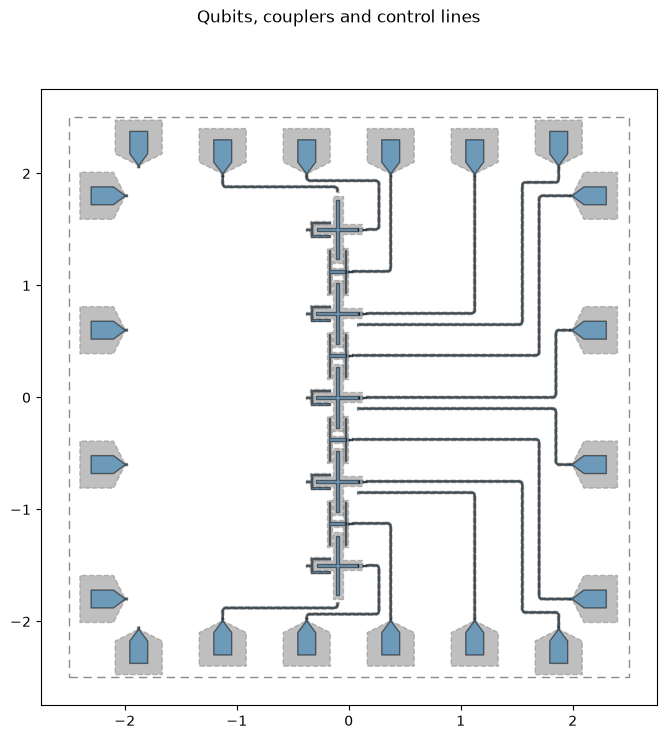

In [9]:
fig = qm.view(design)
fig.suptitle("Qubits, couplers and control lines")
fig

In [10]:
# Capacitance check (set run_capacitance_check = True in the parameters).
# Solves the islands' capacitances on the built layout with capacitance.py and
# prints the frequencies the shared junctions give with them, scaled by the
# HFSS calibration factors in the parameters. If they miss
# their targets, update the C_sigma tables in the parameters.
if run_capacitance_check:
    mid = n_qubits // 2
    probes = {
        "Q0": (qubit_column_x_mm, qubit_y(0)),  # edge qubit: one coupler
        f"Q{mid}": (qubit_column_x_mm, qubit_y(mid)),  # inner qubit: two couplers
        f"TC{mid - 1}": (qubit_column_x_mm, (qubit_y(mid - 1) + qubit_y(mid)) / 2),
    }
    # The claw has no resonator here, so it is its own conductor; held at 0 V
    # with everything else, as the resonator holds it in the full chip.
    rx, ry = design.components[f"Q{mid}"].pins["readout"].middle
    probes["claw"] = (rx + 0.003, ry)
    window = (qubit_column_x_mm - 0.55, qubit_column_x_mm + 0.45,
              qubit_y(0) - 0.5, qubit_y(mid) + qubit_pitch_mm * 0.9)
    rows = capacitance_rows(design, window, probes, pixel_um=1.5, eps_r=substrate_eps_r)
    for name in ("Q0", f"Q{mid}", f"TC{mid - 1}"):
        s = squids[name]
        factor = qubit_csigma_hfss_factor if name.startswith("Q") else coupler_csigma_hfss_factor
        c = rows[name][name] * factor + s["cj_ff"]  # as HFSS will see it
        f, alpha = transmon_levels(s["ej_ghz"], EC_GHZ_FF / c)
        alpha *= anharmonicity_hfss_factor
        print(f"  {name}: C_sigma {c:6.1f} fF (target {s['csigma_ff']:.1f}) -> "
              f"f_max {f:.3f} GHz (target {s['freq_ghz']:.2f}), alpha {alpha * 1e3:.0f} MHz")
    print(f"  qubit-coupler {-rows[f'Q{mid}'][f'TC{mid - 1}']:.2f} fF, "
          f"qubit-claw {-rows[f'Q{mid}']['claw']:.2f} fF")

  Q0: C_sigma  116.3 fF (target 115.7) -> f_max 5.037 GHz (target 5.05), alpha -173 MHz
  Q2: C_sigma  142.1 fF (target 143.5) -> f_max 4.571 GHz (target 4.55), alpha -141 MHz
  TC1: C_sigma  145.0 fF (target 144.5) -> f_max 6.339 GHz (target 6.35), alpha -135 MHz
  qubit-coupler 4.01 fF, qubit-claw 5.93 fF


## HFSS simulations

Eigenmode + EPR simulations of three elements at a time, each switched on in the parameters cell (`run_hfss_*`). Every run includes the XY pads, XY lines and flux lines of its three elements, each line ending in a 50 ohm port where it meets its launchpad, so each mode's Q gives the T1 limit from those lines.

* **Qubit-coupler-qubit** (`run_hfss_coupler_epr`). Each coupler with its two qubits: the coupler frequency, the qubit-coupler couplings, the effective qubit-qubit coupling and the static ZZ.
* **Coupler-qubit-coupler** (`run_hfss_qubit_epr`). Each inner qubit with its two couplers: the qubit with both of its neighbours loading it, and the coupler-coupler cross-talk through the qubit.
* **Array** (`run_hfss_array_epr`). All nine elements at once. It crashed AEDT on this machine and is off.

With `hfss_use_mirror_symmetry` (the default) only the runs on the south half of the chain are simulated; the chain is mirror symmetric about the middle qubit, so each north run's results are its south twin's with the elements relabelled (Q0 <-> Q4, Q1 <-> Q3, TC0 <-> TC3, TC1 <-> TC2), shown as `... (mirror)`.

Each eigenmode run converges on the complex frequency, and its real frequency and Q per adaptive pass are plotted and saved (`<run>_convergence.csv`), with a warning if any mode's Q has not settled.

At the end, every element's frequency, anharmonicity and T1 limit is tabulated against each run it was in.

No readout resonators are rendered (they are in `readout.ipynb`): each claw is shorted to ground where its resonator would start, which is close to what the resonator does at the qubit frequencies. A coupler whose other qubit is not rendered keeps ground plane in that slot, as it is drawn.

Each run of these cells starts a new AEDT project, saved next to this notebook as `hfss_project_file`, or with `_2`, `_3`, ... added if that file exists. Each simulation is a separate design in it.


In [11]:
# Shared by the HFSS cells below. Each junction gets its own HFSS variable
# (Lj_Q0, Lj_TC1, ...) set to the L_J from the junction cell, and a junction
# capacitance (Cj_Q0, ...), so EPR can match variables to junctions. Rebuilding the elements writes the variable names
# into the junction table; no geometry moves.
hfss_on = run_hfss_array_epr or run_hfss_coupler_epr or run_hfss_qubit_epr
hfss_results = {}

if hfss_on:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import pyEPR as epr
    from qiskit_metal.analyses.quantization import EPRanalysis
    
    # A new AEDT project for this run, saved at once under an unused name.
    # The renderer then attaches to it by name before every simulation, so
    # the designs cannot land in whichever project happens to be active.
    stem, ext = os.path.splitext(os.path.abspath(hfss_project_file))
    hfss_project_path, k = stem + ext, 2
    while os.path.exists(hfss_project_path):
        hfss_project_path, k = f"{stem}_{k}{ext}", k + 1
    hfss = design.renderers.hfss
    # AEDT 2024 R2. Started only if no 2024 R2 copy is open already: the
    # renderer attaches to an AEDT that is already running, so starting
    # another (or a different version) just leaves extra windows, and several
    # open copies can stall the connection.
    import subprocess

    running = subprocess.run(
        ["powershell", "-NoProfile", "-Command",
         "(Get-Process ansysedt -ErrorAction SilentlyContinue).Path"],
        capture_output=True, text=True,
    ).stdout
    if "v242" not in running:
        design.renderers.hfss.open_ansys(path_var="ANSYSEM_ROOT242")
    # Make and save the new project over pyEPR's own connection to AEDT,
    # before the renderer connects: hfss.start() attaches to whichever
    # project and design are active and loads their setup, which fails if
    # that is some other project with a setup pyEPR cannot read.
    from pyEPR.ansys import HfssApp

    HfssApp().get_app_desktop().new_project().save(hfss_project_path)
    hfss.options.project_name = os.path.splitext(os.path.basename(hfss_project_path))[0]
    hfss.options.project_path = None
    hfss.start()  # connects to the new project, by name
    print(f"HFSS project: {hfss_project_path} (AEDT {hfss.rdesktop.get_version()})")
    # The substrate (see Chip in the parameters), as a project material that
    # every design in the project draws the chip from.
    hfss.pinfo.project._project.GetDefinitionManager().AddMaterial(
        [f"NAME:{substrate_material}", "CoordinateSystemType:=", "Cartesian",
         "BulkOrSurfaceType:=", 1, ["NAME:PhysicsTypes", "set:=", ["Electromagnetic"]],
         "permittivity:=", str(substrate_eps_r), "dielectric_loss_tangent:=", "0"]
    )
    print(f"Substrate: {substrate_material}, eps_r {substrate_eps_r}, {substrate_thickness_um} um")

    for name in squids:
        element = design.components[name]
        element.options.hfss_inductance = f"Lj_{name}"
        element.options.hfss_capacitance = f"Cj_{name}"
        element.rebuild()
    hfss_vars = Dict({f"Lj_{name}": f"{s['lj_nh']:.4f} nH" for name, s in squids.items()})
    hfss_vars.update({f"Cj_{name}": f"{s['cj_ff']:.3f} fF" for name, s in squids.items()})
    # The junction table, for scqubits_analysis.ipynb (design E_J, C_j, targets).
    os.makedirs(hfss_results_dir, exist_ok=True)
    pd.DataFrame(squids).T.to_csv(os.path.join(hfss_results_dir, "junctions.csv"))


def hfss_buffer(sim):
    sim.renderer.options.x_buffer_width_mm = hfss_buffer_mm
    sim.renderer.options.y_buffer_width_mm = hfss_buffer_mm


# Mirror symmetry about the middle qubit (see hfss_use_mirror_symmetry).
import re

if hfss_use_mirror_symmetry:
    assert qubit_freqs_ghz == qubit_freqs_ghz[::-1] and coupler_freqs_ghz == coupler_freqs_ghz[::-1], (
        "hfss_use_mirror_symmetry needs mirror-symmetric qubit_freqs_ghz and "
        "coupler_freqs_ghz; set it False for this design."
    )


def mirror_label(label):
    """Q1 -> Q3, TC0 -> TC3, ... inside any mode or run label."""
    return re.sub(
        r"\b(TC|Q)(\d+)\b",
        lambda m: f"{m[1]}{(n_qubits - 1 if m[1] == 'Q' else n_qubits - 2) - int(m[2])}",
        label,
    )


def mirror_result(r, sim_name):
    """A run_epr result with every element relabelled to its mirror image,
    standing in for the mirror-image run. Its tables are saved as CSV too."""
    out = dict(r, mirror_of=r.get("sim_name"))
    out["detuned"] = {mirror_label(k): v for k, v in r.get("detuned", {}).items()}
    for kind in ("modes", "chi", "chi_first_order", "convergence"):
        t = r.get(kind)
        if t is None:
            continue
        if kind == "convergence":  # columns (element, quantity), index pass
            t = t.rename(columns=mirror_label, level=0)
        else:
            t = t.rename(index=mirror_label)
        if kind in ("chi", "chi_first_order"):
            t = t.rename(columns=mirror_label)
        out[kind] = t
        t.to_csv(os.path.join(hfss_results_dir, f"{sim_name}_{kind}.csv"))
    print(f"\n{sim_name}: mirror image of {r.get('sim_name')}, not simulated")
    print(out["modes"].round(4).to_string())
    return out


def run_name(qubit_ids, coupler_ids):
    """Q0_TC0_Q1, TC1_Q2_TC2, ...: the elements in order up the chain."""
    pos = {**{f"Q{q}": q for q in qubit_ids}, **{f"TC{c}": c + 0.5 for c in coupler_ids}}
    return "_".join(sorted(pos, key=pos.get))


def get_run(qubit_ids, coupler_ids):
    """run_epr on these elements, or with hfss_use_mirror_symmetry, the mirror
    image of the south-half run when this one is centred north of the middle
    qubit. Results are kept in hfss_results, so each simulation is done once."""
    sim_name = run_name(qubit_ids, coupler_ids)
    pos = list(qubit_ids) + [c + 0.5 for c in coupler_ids]
    if hfss_use_mirror_symmetry and sum(pos) / len(pos) > (n_qubits - 1) / 2:
        twin_q = [n_qubits - 1 - q for q in qubit_ids]
        twin_c = [n_qubits - 2 - c for c in coupler_ids]
        twin = run_name(twin_q, twin_c)
        if twin not in hfss_results:
            hfss_results[twin] = run_epr(twin, twin_q, twin_c)
        key = f"{sim_name} (mirror)"
        if key not in hfss_results:
            hfss_results[key] = mirror_result(hfss_results[twin], sim_name)
        return hfss_results[key]
    if sim_name not in hfss_results:
        hfss_results[sim_name] = run_epr(sim_name, qubit_ids, coupler_ids)
    return hfss_results[sim_name]


ISLAND_SHEET = re.compile(r"^(cross_Q\d+|island_TC\d+|head_(Q|TC)\d+_claw)$")


def seed_island_mesh(renderer):
    """Mesh length operation (hfss_island_mesh_um) on every qubit cross,
    coupler island and claw head in the rendered design, so the first adaptive
    pass already resolves the field round the islands."""
    if not hfss_island_mesh_um:
        return
    sheets = [o for o in renderer.modeler.get_objects_in_group("Sheets")
              if ISLAND_SHEET.match(o)]
    if not sheets:
        print("  WARNING: no island sheets found to seed the mesh on; "
              "check ISLAND_SHEET against the object names in AEDT.")
        return
    renderer.modeler.mesh_length("island_mesh", sheets, MaxLength=f"{hfss_island_mesh_um}um")
    print(f"  Mesh seed: {hfss_island_mesh_um} um on {', '.join(sorted(sheets))}")


def converge_on_complex_freq(renderer, s):
    """Make the next eigenmode setup the renderer runs converge on the complex
    frequency (hfss_converge_on_real_freq). pyEPR always creates the setup with
    ConvergeOnRealFreq True, so it is edited just before it is analysed, with
    every other setting as given in s (the sim's setup). The island mesh seed
    is added here too: the design is drawn by then and not yet solved."""
    analyze = type(renderer).analyze_setup

    def analyze_setup(setup_name):
        seed_island_mesh(renderer)
        renderer.pinfo.design._setup_module.EditSetup(setup_name, [
            f"NAME:{setup_name}",
            "MinimumFrequency:=", f"{s.min_freq_ghz}GHz",
            "NumModes:=", int(s.n_modes),
            "MaxDeltaFreq:=", float(s.max_delta_f),
            "ConvergeOnRealFreq:=", bool(hfss_converge_on_real_freq),
            "MaximumPasses:=", int(s.max_passes),
            "MinimumPasses:=", int(s.min_passes),
            "MinimumConvergedPasses:=", int(s.min_converged),
            "PercentRefinement:=", int(s.pct_refinement),
            "IsEnabled:=", True,
            "BasisOrder:=", int(s.basis_order),
        ])
        print(f"Setup {setup_name}: converging on the "
              f"{'real' if hfss_converge_on_real_freq else 'complex'} frequency, "
              f"max delta f {s.max_delta_f} %, {s.min_converged} passes in a row")
        analyze(renderer, setup_name)

    renderer.analyze_setup = analyze_setup


_UNIT_HZ = {"": 1.0, "hz": 1.0, "khz": 1e3, "mhz": 1e6, "g": 1e9, "ghz": 1e9}


def complex_convergence(eig, sim_name, names, kappas):
    """Real frequency (GHz) and Q of every mode at every adaptive pass, from
    an HFSS report of re(Mode(i)) and im(Mode(i)). Saved as CSV, plotted, and
    checked: prints the last pass's change in f and Q per mode, with a warning
    if Q has not settled to hfss_max_delta_q_pct."""
    renderer = eig.sim.renderer
    setup = renderer.pinfo.setup
    report = renderer.pinfo.design._reporter
    n = len(names)
    title = "Complex freq. vs. pass"
    if title in report.GetAllReportNames():
        report.DeleteReports([title])
    ycomp = [f"{part}(Mode({i}))" for i in range(1, n + 1) for part in ("re", "im")]
    setup.get_solutions().create_report(title, "Pass", ycomp, ["Pass:=", ["All"]],
                                        pass_name="AdaptivePass")
    os.makedirs(hfss_results_dir, exist_ok=True)
    raw_path = os.path.abspath(os.path.join(hfss_results_dir, f"{sim_name}_convergence_raw.csv"))
    report.ExportToFile(title, raw_path)
    raw = pd.read_csv(raw_path, index_col=0)

    def column(part, i):
        # Headers look like 're(Mode(1)) [g]'; the bracket is the unit.
        col = next(c for c in raw.columns if c.startswith(f"{part}(Mode({i}))"))
        unit = re.search(r"\[(.*?)\]", col)
        return raw[col].astype(float) * _UNIT_HZ.get((unit[1] if unit else "").strip().lower(), 1.0)

    conv = {}
    for i, name in enumerate(names, start=1):
        f_hz, im_hz = column("re", i), column("im", i)
        conv[(name, "f (GHz)")] = f_hz / 1e9
        conv[(name, "Q")] = f_hz / (2 * im_hz.abs()).replace(0, np.nan)
    conv = pd.DataFrame(conv)
    conv.index.name = "pass"
    conv.to_csv(os.path.join(hfss_results_dir, f"{sim_name}_convergence.csv"))

    lossy = bool(conv.xs("Q", axis=1, level=1).notna().any().any())
    if kappas is not None and lossy:  # the report's last pass against the solution
        k = np.asarray(kappas, dtype=float)
        k = k / 1e9 if k.max() > 1e3 else k
        q_sol = conv.xs("f (GHz)", axis=1, level=1).iloc[-1].values / k
        q_rep = conv.xs("Q", axis=1, level=1).iloc[-1].values
        if not np.allclose(q_rep, q_sol, rtol=0.05, equal_nan=True):
            print("  WARNING: Q from the pass report disagrees with the final solution "
                  f"({np.round(q_rep, 0)} vs {np.round(q_sol, 0)}): check the report's units.")

    last = {}
    for name in names:
        f, q = conv[(name, "f (GHz)")], conv[(name, "Q")]
        row = {"f (GHz)": f.iloc[-1],
               "last delta f (%)": abs(f.iloc[-1] / f.iloc[-2] - 1) * 100 if len(f) > 1 else np.nan}
        if lossy:
            row["Q"] = q.iloc[-1]
            row["last delta Q (%)"] = abs(q.iloc[-1] / q.iloc[-2] - 1) * 100 if len(q) > 1 else np.nan
        last[name] = row
    last = pd.DataFrame(last).T
    print(f"\n{sim_name}: convergence after {len(conv)} passes "
          f"(criterion: {hfss_max_delta_f} % on the "
          f"{'real' if hfss_converge_on_real_freq else 'complex'} frequency)")
    print(last.round(5).to_string())
    if lossy:
        slow = last.index[last["last delta Q (%)"] > hfss_max_delta_q_pct]
        if len(slow):
            print(f"  WARNING: Q of {', '.join(slow)} still moved more than "
                  f"{hfss_max_delta_q_pct} % on the last pass; its T1 limit is not "
                  "converged. Raise hfss_max_passes or tighten hfss_max_delta_f.")

    fig, axes = plt.subplots(1, 2 if lossy else 1, figsize=(11 if lossy else 6, 3.5), squeeze=False)
    for name in names:
        axes[0, 0].plot(conv.index, conv[(name, "f (GHz)")], "o-", label=name)
        if lossy:
            axes[0, 1].semilogy(conv.index, conv[(name, "Q")], "o-", label=name)
    axes[0, 0].set(xlabel="pass", ylabel="Re f (GHz)", title=f"{sim_name}: real frequency")
    axes[0, 0].legend(fontsize=8)
    if lossy:
        axes[0, 1].set(xlabel="pass", ylabel="Q = Re f / (2 Im f)", title=f"{sim_name}: Q")
    fig.tight_layout()
    plt.show()
    return conv


# Quantum analysis. pyEPR gets each mode's anharmonicity and the cross-Kerr
# shifts by numerically diagonalising the junction Hamiltonian in a Fock space
# of fock_trunc ** (number of modes) states, as one dense matrix: it cannot be
# interrupted, and 7 ** 5 states already takes hours. fock_trunc must still be
# 7 or more: at 5, anharmonicities come out ~20 MHz low and the ZZ ten times
# too big. So runs with more than 4 modes are diagonalised in small groups:
# each coupler with its two qubits. Pairs of modes that
# share no group are left blank (NaN) in chi; pyEPR's first-order estimate of
# every pair is kept as chi_first_order, but it gets ZZ badly wrong.
def epr_groups(index, qubit_ids, coupler_ids):
    """Lists of mode numbers to diagonalise together, given {label: mode}."""
    if len(index) <= 4:
        return [sorted(index.values())]
    groups = [[f"Q{c}", f"TC{c}", f"Q{c + 1}"] for c in coupler_ids]
    groups = [sorted(index[k] for k in g if k in index) for g in groups]
    return [g for g in groups if g]


def control_parts(elements):
    """Control lines (and XY pads) of these elements, and a port on each line
    where it meets its launchpad (the launchpads are not rendered)."""
    starts = set(elements) | {f"XY_pad_{e[1:]}" for e in elements if e.startswith("Q")}
    lines = [(name, start) for name, start, *_ in control_lines if start in starts]
    parts = [name for name, _ in lines]
    parts += [start for _, start in lines if start.startswith("XY_pad")]
    ports = [(name, "end", hfss_control_line_ohms) for name, _ in lines]
    return parts, ports


def run_epr(sim_name, qubit_ids, coupler_ids):
    """Eigenmode + EPR of some qubits and couplers (and their control lines,
    if hfss_include_control_lines).

    Returns the table of modes and the matrix of cross-Kerr shifts (MHz), and
    writes both to hfss_results_dir as CSV as soon as they exist.
    """
    elements = [f"Q{i}" for i in qubit_ids] + [f"TC{i}" for i in coupler_ids]
    lines, ports = control_parts(elements) if hfss_include_control_lines else ([], [])
    n_modes = len(elements)  # one per qubit and coupler

    # Detune elements that would hybridise with one already in this run (see
    # hfss_degenerate_mhz), and move their targets with them.
    run_vars = Dict(hfss_vars)
    targets = {name: squids[name]["freq_ghz"] for name in elements}
    detuned = {}
    for k, name in enumerate(elements):
        if any(abs(targets[name] - targets[e]) * 1e3 < hfss_degenerate_mhz for e in elements[:k]):
            lj = squids[name]["lj_nh"] * (1 + hfss_degenerate_lj_detune)
            run_vars[f"Lj_{name}"] = f"{lj:.4f} nH"
            targets[name] /= (1 + hfss_degenerate_lj_detune) ** 0.5
            detuned[name] = lj
    if detuned:
        print(f"{sim_name}: L_J raised {hfss_degenerate_lj_detune:.0%} on "
              f"{', '.join(detuned)} so it does not hybridise with an element at the "
              "same frequency; its results here are at the detuned point "
              f"(target {', '.join(f'{targets[n]:.3f}' for n in detuned)} GHz).")

    eig = EPRanalysis(design, "hfss")
    hfss_buffer(eig.sim)
    eig.sim.setup.update(
        n_modes=n_modes,
        min_freq_ghz=0.5 * min(min(qubit_freqs_ghz), min(coupler_freqs_ghz)),
        max_passes=hfss_max_passes,
        min_converged=hfss_min_converged,
        max_delta_f=hfss_max_delta_f,
        basis_order=hfss_basis_order,
        vars=run_vars,
    )
    converge_on_complex_freq(eig.sim.renderer, eig.sim.setup)
    # open_terminations=[]: every pin left unconnected (the claws, and the
    # flux T's when their lines are not rendered) is shorted to ground.
    heads = [f"{e}_claw" for e in elements]  # base metal round each island claw
    eig.sim.run(name=sim_name, components=elements + heads + lines, open_terminations=[],
                port_list=ports)
    eig.sim.plot_convergences()
    # Q of each mode (in HFSS's mode order, the same as pyEPR's): with the
    # control lines ending in resistors, the T1 limit they set is Q / (2 pi f).
    _, kappas = eig.sim.renderer.pinfo.setup.get_solutions().eigenmodes()

    eig.del_junction("jj")
    for element in elements:
        eig.add_junction(
            element,
            lj_var=f"Lj_{element}",
            cj_var=f"Cj_{element}",
            rect=f"JJ_rect_Lj_{element}_rect_jj",
            line=f"JJ_Lj_{element}_rect_jj_",
        )
    # The EPR field integrals, in HFSS, written to pyEPR's data file. (Metal's
    # eig.run_epr() would follow this with one diagonalisation of every mode.)
    eig.clear_data()
    eig.get_stored_energy()
    eig.run_analysis()
    qa = epr.QuantumAnalysis(eig.sim.renderer.epr_distributed_analysis.data_filename)
    variation = qa.variations[0]

    # First order (analytic, every mode at once): enough to name the modes.
    o1 = qa.analyze_variation(variation, cos_trunc=None, fock_trunc=None, print_result=False)
    junctions = list(o1["Ljs"].index)
    f_mhz = np.real(np.asarray(o1["f_1"], dtype=complex))
    chi_o1 = np.real(np.asarray(o1["chi_O1"], dtype=complex))
    pj = np.asarray(o1["Pm_normed"], dtype=float).reshape(len(f_mhz), -1)

    # Name each mode: the junction holding most of its inductive energy.
    labels = {}
    for m in np.argsort(f_mhz):
        name = junctions[int(pj[m].argmax())] if pj[m].max() > 0.1 else f"mode {m}"
        if name in labels.values():
            name = f"{name} (mode {m})"
        labels[int(m)] = name
    names = [labels[m] for m in range(len(f_mhz))]
    for m in range(len(f_mhz)):
        if pj[m].max() < hfss_min_participation:
            shares = ", ".join(f"{j} {p:.2f}" for j, p in zip(junctions, pj[m]) if p > 0.05)
            print(f"  WARNING: mode {labels[m]} ({f_mhz[m] / 1e3:.3f} GHz) is mixed: "
                  f"junction participation {shares}. Its anharmonicity, couplings "
                  "and ZZ are not those of one element; detune the elements "
                  "(hfss_degenerate_mhz) or check the mode labels.")
    index = {name: m for m, name in labels.items()}
    convergence = complex_convergence(eig, sim_name, names, kappas)

    # Numerical diagonalisation, group by group (see above).
    chi_mhz = np.full_like(chi_o1, np.nan)
    for group in epr_groups(index, qubit_ids, coupler_ids):
        nd = qa.analyze_variation(
            variation,
            cos_trunc=8,
            fock_trunc=8 if len(group) <= 3 else 7,
            print_result=False,
            modes=group,
        )
        f_nd = np.real(np.asarray(nd["f_ND"], dtype=complex))
        chi_nd = np.real(np.asarray(nd["chi_ND"], dtype=complex))
        for a, m in enumerate(group):
            f_mhz[m] = f_nd[a]
            chi_mhz[m, group] = chi_nd[a]

    modes = pd.DataFrame(
        {
            "f (GHz)": f_mhz / 1e3,
            "target (GHz)": [targets.get(name, np.nan) for name in names],
            "|anharmonicity| (MHz)": np.diag(chi_mhz),
            "max junction participation": pj.max(axis=1),
        },
        index=names,
    )
    if ports and kappas is not None:
        k = np.asarray(kappas, dtype=float)
        k = k / 1e9 if k.max() > 1e3 else k  # GHz (exported in Hz by some versions)
        modes["Q"] = modes["f (GHz)"] / k
        modes["T1 limit (us)"] = modes["Q"] / (2 * np.pi * modes["f (GHz)"] * 1e3)
    modes = modes.sort_values("f (GHz)")
    order = modes.index
    chi = pd.DataFrame(chi_mhz, index=names, columns=names).loc[order, order]
    chi_first_order = pd.DataFrame(chi_o1, index=names, columns=names).loc[order, order]

    os.makedirs(hfss_results_dir, exist_ok=True)
    for table, kind in ((modes, "modes"), (chi, "chi"), (chi_first_order, "chi_first_order")):
        table.to_csv(os.path.join(hfss_results_dir, f"{sim_name}_{kind}.csv"))

    print(f"\n{sim_name}: modes (numerical diagonalisation)")
    print(modes.round(4).to_string())
    print("\nCross-Kerr shifts (MHz): one excitation in the row's mode shifts the")
    print("column's mode down by this much. Diagonal: the mode's own |anharmonicity|.")
    print("NaN: the two modes were not diagonalised together.")
    print(chi.round(3).to_string())
    print(f"(saved to {hfss_results_dir}/{sim_name}_*.csv)")
    return dict(modes=modes, chi=chi, chi_first_order=chi_first_order,
                convergence=convergence, analysis=eig, sim_name=sim_name,
                detuned=detuned)


def coupling_mhz(r, x, y):
    """Coupling g (MHz) between modes x and y of a run_epr result.

    From their cross-Kerr shift: for two coupled transmons, to lowest order,
    chi = 2 g^2 (a_x + a_y) / ((D + a_x)(D - a_y)), D = f_x - f_y, with the
    anharmonicities a negative. Valid while g << |D|.
    """
    f = r["modes"]["f (GHz)"] * 1e3
    chi = r["chi"]
    ax, ay = -chi.loc[x, x], -chi.loc[y, y]
    d = f[x] - f[y]
    return np.sqrt(abs(chi.loc[x, y] * (d + ax) * (d - ay) / (2 * (ax + ay))))


def coupler_summary_row(r, c):
    """Couplings and static ZZ around coupler c, from a run_epr result."""
    qa, tc, qb = f"Q{c}", f"TC{c}", f"Q{c + 1}"
    f = r["modes"]["f (GHz)"] * 1e3
    chi = r["chi"]
    g1, g2 = coupling_mhz(r, qa, tc), coupling_mhz(r, tc, qb)
    # Exchange between the qubits through the coupler (Yan et al. 2018). Any
    # direct qubit-qubit coupling adds to it; these runs do not separate it.
    geff = g1 * g2 / 2 * sum(1 / (f[q] - f[tc]) - 1 / (f[q] + f[tc]) for q in (qa, qb))
    detuning = f[qb] - f[qa]
    return {
        "f TC (GHz)": f[tc] / 1e3,
        "Q-Q detuning (MHz)": detuning,
        # |11> meets |02> or |20> when the detuning equals an anharmonicity.
        "detuning - |anharm.| (MHz)": min(abs(detuning) - chi.loc[q, q] for q in (qa, qb)),
        "g Qa-TC (MHz)": g1,
        "g TC-Qb (MHz)": g2,
        "g_eff via TC (MHz)": geff,
        "static ZZ (kHz)": -chi.loc[qa, qb] * 1e3,
    }


def qubit_summary_row(r, q):
    """Couplings around inner qubit q (couplers TC(q-1) and TCq), from a
    run_epr result."""
    ta, qb, tb = f"TC{q - 1}", f"Q{q}", f"TC{q}"
    f = r["modes"]["f (GHz)"]
    chi = r["chi"]
    return {
        "f Q (GHz)": f[qb],
        "|anharm.| Q (MHz)": chi.loc[qb, qb],
        "g TCa-Q (MHz)": coupling_mhz(r, ta, qb),
        "g Q-TCb (MHz)": coupling_mhz(r, qb, tb),
        # Cross-Kerr between the two couplers, through the qubit (and directly)
        "chi TCa-TCb (kHz)": chi.loc[ta, tb] * 1e3,
    }


INFO 03:46PM [connect_project]: Connecting to Ansys Desktop API...
INFO 03:46PM [load_ansys_project]: 	Opened Ansys App
INFO 03:46PM [load_ansys_project]: 	Opened Ansys Desktop v2024.2.0
INFO 03:46PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    c:/Users/Crow104/Desktop/Orion/qiskit_metal_tests/five_plus_four/
	Project:   qubits_couplers_hfss
INFO 03:46PM [connect_design]: No active design found (or error getting active design).
INFO 03:46PM [connect]: 	 Connected to project "qubits_couplers_hfss". No design detected


HFSS project: c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\qubits_couplers_hfss.aedt (AEDT 2024.2.0)
Substrate: silicon_bisquit, eps_r 11.45, 725 um


INFO 03:46PM [connect_design]: 	Opened active design
	Design:    Q0_TC0_Q1_hfss [Solution type: Eigenmode]
WARNING 03:46PM [connect_setup]: 	No design setup detected.
WARNING 03:46PM [connect_setup]: 	Creating eigenmode default setup.
INFO 03:46PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 03:46PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 03:46PM [analyze]: Analyzing setup Setup


Setup Setup: converging on the real frequency, max delta f 0.1 %, 2 passes in a row


04:09PM 51s INFO [get_f_convergence]: Saved convergences to c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\hfss_eig_f_convergence.csv
INFO 04:09PM [__init__]: Design "Q0_TC0_Q1_hfss" info:
INFO 04:09PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 04:09PM [__init__]: Design "Q0_TC0_Q1_hfss" info:
INFO 04:09PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 04:10PM [do_EPR_analysis]: Variation 0  [1/1]



        energy_elec_all       = 1.6610260145617e-26
        energy_elec_substrate = 1.52641101363867e-26
        EPR of substrate = 91.9%

        energy_mag    = 2.49646473312679e-28
        energy_mag % of energy_elec_all  = 1.5%
        


INFO 04:10PM [do_EPR_analysis]: Mode 0 at 5.06 GHz   [1/3]
INFO 04:10PM [do_EPR_analysis]:     Calculating E_magnetic ...
INFO 04:10PM [do_EPR_analysis]:     Calculating E_electric ...
INFO 04:10PM [do_EPR_analysis]:      (E_E-E_H)/E_E=  98.5%   E_E=8.305e-27   E_H=1.248e-28
INFO 04:10PM [do_EPR_analysis]:     Calculating junction EPR, method=`line_voltage`
INFO 04:10PM [do_EPR_analysis]: 	junction        EPR p_0j   sign s_0j    (p_capacitive)
INFO 04:10PM [calc_p_junction]: 	Q0              3.28073e-06  (+)        5.33273e-08
INFO 04:10PM [calc_p_junction]: 	Q1               1.01735  (-)        0.0165368
INFO 04:10PM [calc_p_junction]: 	TC0             0.00162395  (+)        1.36996e-05
INFO 04:10PM [calc_p_junction]: 		(U_tot_cap-U_tot_ind)/mean=-0.85%
INFO 04:10PM [get_Qdielectric]: Calculating Qdielectric_main for mode 0 (0/2)
INFO 04:10PM [get_Qdielectric]: p_dielectric_main_0 = 0.9189567172681811
INFO 04:10PM [do_EPR_analysis]: Mode 1 at 5.31 GHz   [2/3]
INFO 04:10PM [do_EPR_anal


Q0_TC0_Q1: convergence after 80 passes (criterion: 0.1 % on the real frequency)
     f (GHz)  last delta f (%)
Q1       NaN               NaN
Q0       NaN               NaN
TC0      NaN               NaN


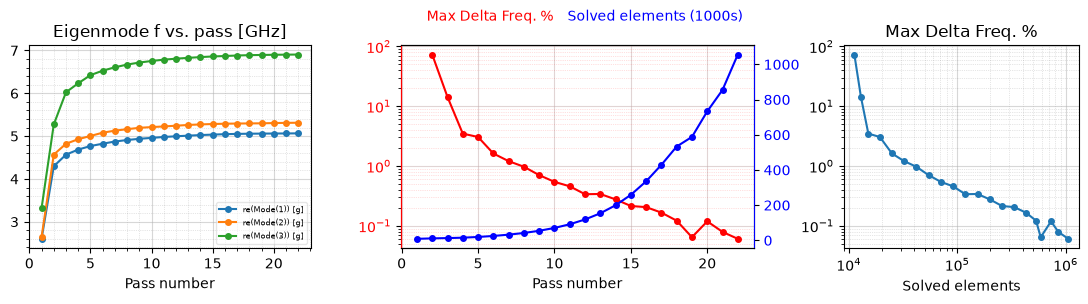

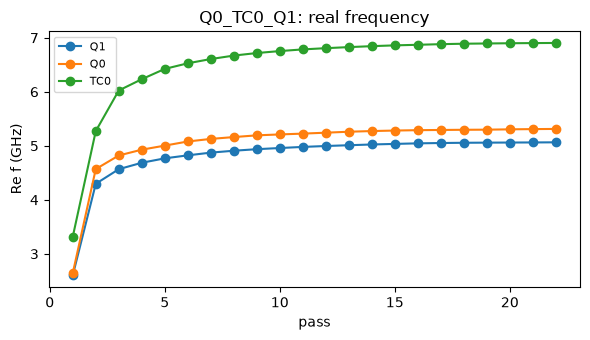

INFO 04:11PM [analyze_variation]: Variation 0
INFO 04:11PM [make_dispersive]: Starting diagonalization (512×512 matrix)
INFO 04:11PM [make_dispersive]: Diagonalization complete



Q0_TC0_Q1: modes (numerical diagonalisation)
     f (GHz)  target (GHz)  |anharmonicity| (MHz)  max junction participation
Q1    4.9066          4.80               164.0045                      0.9838
Q0    5.1387          5.05               180.6271                      0.9823
TC0   6.7540          6.60               153.2446                      0.9798

Cross-Kerr shifts (MHz): one excitation in the row's mode shifts the
column's mode down by this much. Diagonal: the mode's own |anharmonicity|.
NaN: the two modes were not diagonalised together.
          Q1       Q0      TC0
Q1   164.004    0.009    0.988
Q0     0.009  180.627    1.243
TC0    0.988    1.243  153.245
(saved to hfss_results/qubits_couplers/Q0_TC0_Q1_*.csv)


INFO 04:11PM [connect_design]: 	Opened active design
	Design:    Q1_TC1_Q2_hfss [Solution type: Eigenmode]
WARNING 04:11PM [connect_setup]: 	No design setup detected.
WARNING 04:11PM [connect_setup]: 	Creating eigenmode default setup.
INFO 04:11PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 04:12PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 04:12PM [analyze]: Analyzing setup Setup


Setup Setup: converging on the real frequency, max delta f 0.1 %, 2 passes in a row


04:25PM 07s INFO [get_f_convergence]: Saved convergences to c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\hfss_eig_f_convergence.csv
INFO 04:25PM [__init__]: Design "Q1_TC1_Q2_hfss" info:
INFO 04:25PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 04:25PM [__init__]: Design "Q1_TC1_Q2_hfss" info:
INFO 04:25PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 04:25PM [do_EPR_analysis]: Variation 0  [1/1]



        energy_elec_all       = 4.88278325091318e-26
        energy_elec_substrate = 4.48513676904643e-26
        EPR of substrate = 91.9%

        energy_mag    = 6.72292722387066e-28
        energy_mag % of energy_elec_all  = 1.4%
        


INFO 04:25PM [do_EPR_analysis]: Mode 0 at 4.80 GHz   [1/3]
INFO 04:25PM [do_EPR_analysis]:     Calculating E_magnetic ...
INFO 04:25PM [do_EPR_analysis]:     Calculating E_electric ...
INFO 04:25PM [do_EPR_analysis]:      (E_E-E_H)/E_E=  98.6%   E_E=2.441e-26   E_H=3.361e-28
INFO 04:25PM [do_EPR_analysis]:     Calculating junction EPR, method=`line_voltage`
INFO 04:25PM [do_EPR_analysis]: 	junction        EPR p_0j   sign s_0j    (p_capacitive)
INFO 04:25PM [calc_p_junction]: 	Q1              1.64187e-06  (+)        2.40014e-08
INFO 04:25PM [calc_p_junction]: 	Q2               1.01508  (-)        0.0148388
INFO 04:25PM [calc_p_junction]: 	TC1             0.00190655  (+)        1.44644e-05
INFO 04:25PM [calc_p_junction]: 		(U_tot_cap-U_tot_ind)/mean=-0.78%
INFO 04:25PM [get_Qdielectric]: Calculating Qdielectric_main for mode 0 (0/2)
INFO 04:25PM [get_Qdielectric]: p_dielectric_main_0 = 0.9185615126798058
INFO 04:25PM [do_EPR_analysis]: Mode 1 at 5.05 GHz   [2/3]
INFO 04:25PM [do_EPR_anal


Q1_TC1_Q2: convergence after 80 passes (criterion: 0.1 % on the real frequency)
     f (GHz)  last delta f (%)
Q2       NaN               NaN
Q1       NaN               NaN
TC1      NaN               NaN


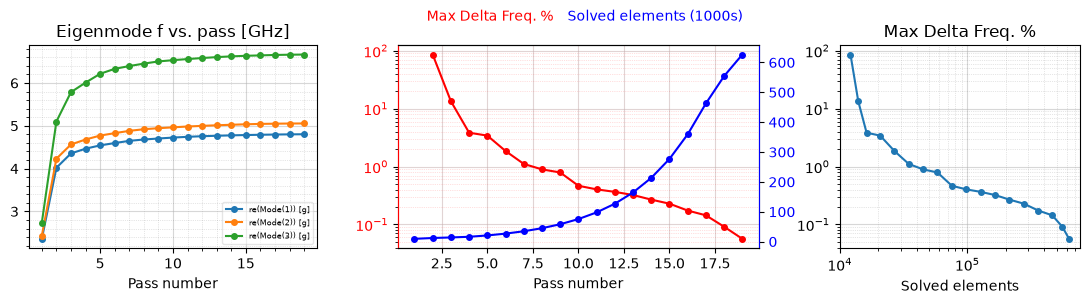

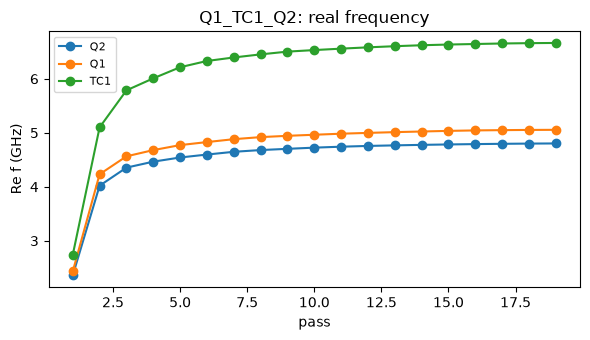

INFO 04:26PM [analyze_variation]: Variation 0
INFO 04:26PM [make_dispersive]: Starting diagonalization (512×512 matrix)
INFO 04:26PM [make_dispersive]: Diagonalization complete



Q1_TC1_Q2: modes (numerical diagonalisation)
     f (GHz)  target (GHz)  |anharmonicity| (MHz)  max junction participation
Q2    4.6606          4.55               147.2164                      0.9847
Q1    4.8976          4.80               163.2611                      0.9833
TC1   6.5243          6.35               142.2082                      0.9788

Cross-Kerr shifts (MHz): one excitation in the row's mode shifts the
column's mode down by this much. Diagonal: the mode's own |anharmonicity|.
NaN: the two modes were not diagonalised together.
          Q2       Q1      TC1
Q2   147.216    0.004    1.073
Q1     0.004  163.261    1.361
TC1    1.073    1.361  142.208
(saved to hfss_results/qubits_couplers/Q1_TC1_Q2_*.csv)

Q2_TC2_Q3: mirror image of Q1_TC1_Q2, not simulated
     f (GHz)  target (GHz)  |anharmonicity| (MHz)  max junction participation
Q2    4.6606          4.55               147.2164                      0.9847
Q3    4.8976          4.80               163.2611        

In [12]:
# Qubit-coupler-qubit: each coupler in hfss_epr_couplers with the qubits on
# either side (and their control lines). Every junction is at zero flux, so
# each coupler is at its maximum frequency and the Q-Q shift is the static ZZ
# there. Three modes, diagonalised together. The neighbouring couplers are
# not rendered; the coupler-qubit-coupler runs below cover them. With
# hfss_use_mirror_symmetry, TC2 and TC3 are TC1 and TC0 relabelled.
if run_hfss_coupler_epr:
    rows = {}
    for c in hfss_epr_couplers:
        r = get_run([c, c + 1], [c])
        rows[f"TC{c}" + (" (mirror)" if "mirror_of" in r else "")] = coupler_summary_row(r, c)
    coupler_summary = pd.DataFrame(rows).T
    coupler_summary.to_csv(os.path.join(hfss_results_dir, "coupler_summary.csv"))
    print("\nCouplers (Qa = the lower-numbered qubit), each from its own run:")
    print(coupler_summary.round(3).to_string())

INFO 04:26PM [connect_design]: 	Opened active design
	Design:    TC0_Q1_TC1_hfss [Solution type: Eigenmode]
WARNING 04:26PM [connect_setup]: 	No design setup detected.
WARNING 04:26PM [connect_setup]: 	Creating eigenmode default setup.
INFO 04:26PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 04:26PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 04:26PM [analyze]: Analyzing setup Setup


Setup Setup: converging on the real frequency, max delta f 0.1 %, 2 passes in a row


04:46PM 31s INFO [get_f_convergence]: Saved convergences to c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\hfss_eig_f_convergence.csv
INFO 04:46PM [__init__]: Design "TC0_Q1_TC1_hfss" info:
INFO 04:46PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 04:46PM [__init__]: Design "TC0_Q1_TC1_hfss" info:
INFO 04:46PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 04:46PM [do_EPR_analysis]: Variation 0  [1/1]



        energy_elec_all       = 2.8173598289487e-26
        energy_elec_substrate = 2.58829867407354e-26
        EPR of substrate = 91.9%

        energy_mag    = 4.24554270708653e-28
        energy_mag % of energy_elec_all  = 1.5%
        


INFO 04:46PM [do_EPR_analysis]: Mode 0 at 5.06 GHz   [1/3]
INFO 04:46PM [do_EPR_analysis]:     Calculating E_magnetic ...
INFO 04:46PM [do_EPR_analysis]:     Calculating E_electric ...
INFO 04:46PM [do_EPR_analysis]:      (E_E-E_H)/E_E=  98.5%   E_E=1.409e-26   E_H=2.123e-28
INFO 04:46PM [do_EPR_analysis]:     Calculating junction EPR, method=`line_voltage`
INFO 04:46PM [do_EPR_analysis]: 	junction        EPR p_0j   sign s_0j    (p_capacitive)
INFO 04:47PM [calc_p_junction]: 	Q1               1.01476  (-)        0.0164591
INFO 04:47PM [calc_p_junction]: 	TC0             0.00162668  (+)        1.36931e-05
INFO 04:47PM [calc_p_junction]: 	TC1             0.0023995  (+)        2.01986e-05
INFO 04:47PM [calc_p_junction]: 		(U_tot_cap-U_tot_ind)/mean=-0.85%
INFO 04:47PM [get_Qdielectric]: Calculating Qdielectric_main for mode 0 (0/2)
INFO 04:47PM [get_Qdielectric]: p_dielectric_main_0 = 0.9186965212886441
INFO 04:47PM [do_EPR_analysis]: Mode 1 at 6.65 GHz   [2/3]
INFO 04:47PM [do_EPR_analys


TC0_Q1_TC1: convergence after 80 passes (criterion: 0.1 % on the real frequency)
     f (GHz)  last delta f (%)
Q1       NaN               NaN
TC1      NaN               NaN
TC0      NaN               NaN


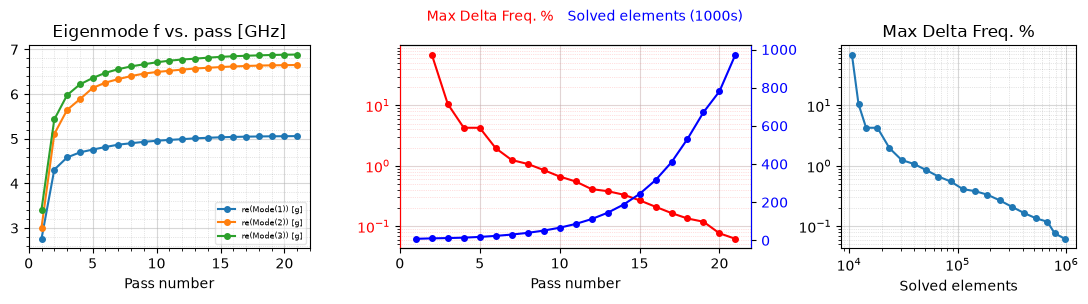

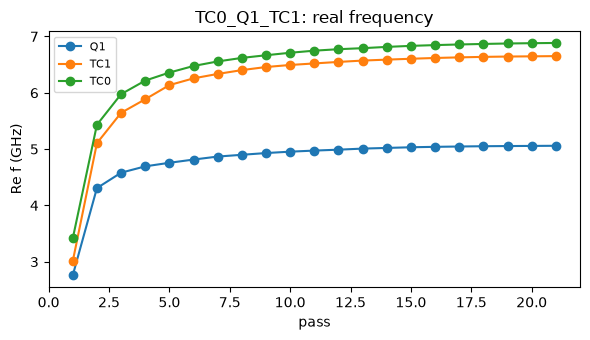

INFO 04:48PM [analyze_variation]: Variation 0
INFO 04:48PM [make_dispersive]: Starting diagonalization (512×512 matrix)
INFO 04:48PM [make_dispersive]: Diagonalization complete



TC0_Q1_TC1: modes (numerical diagonalisation)
     f (GHz)  target (GHz)  |anharmonicity| (MHz)  max junction participation
Q1    4.9014          4.80               163.0134                      0.9814
TC1   6.5117          6.35               142.4200                      0.9812
TC0   6.7352          6.60               152.8461                      0.9822

Cross-Kerr shifts (MHz): one excitation in the row's mode shifts the
column's mode down by this much. Diagonal: the mode's own |anharmonicity|.
NaN: the two modes were not diagonalised together.
          Q1      TC1      TC0
Q1   163.013    1.358    1.016
TC1    1.358  142.420    0.543
TC0    1.016    0.543  152.846
(saved to hfss_results/qubits_couplers/TC0_Q1_TC1_*.csv)


INFO 04:48PM [connect_design]: 	Opened active design
	Design:    TC1_Q2_TC2_hfss [Solution type: Eigenmode]
WARNING 04:48PM [connect_setup]: 	No design setup detected.
WARNING 04:48PM [connect_setup]: 	Creating eigenmode default setup.
INFO 04:48PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 04:48PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 04:48PM [analyze]: Analyzing setup Setup


Setup Setup: converging on the real frequency, max delta f 0.1 %, 2 passes in a row


05:02PM 01s INFO [get_f_convergence]: Saved convergences to c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\hfss_eig_f_convergence.csv
INFO 05:02PM [__init__]: Design "TC1_Q2_TC2_hfss" info:
INFO 05:02PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 05:02PM [__init__]: Design "TC1_Q2_TC2_hfss" info:
INFO 05:02PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 05:02PM [do_EPR_analysis]: Variation 0  [1/1]



        energy_elec_all       = 5.15029879047861e-26
        energy_elec_substrate = 4.73006281289609e-26
        EPR of substrate = 91.8%

        energy_mag    = 7.14690660319665e-28
        energy_mag % of energy_elec_all  = 1.4%
        


INFO 05:02PM [do_EPR_analysis]: Mode 0 at 4.80 GHz   [1/3]
INFO 05:02PM [do_EPR_analysis]:     Calculating E_magnetic ...
INFO 05:02PM [do_EPR_analysis]:     Calculating E_electric ...
INFO 05:02PM [do_EPR_analysis]:      (E_E-E_H)/E_E=  98.6%   E_E=2.575e-26   E_H=3.573e-28
INFO 05:02PM [do_EPR_analysis]:     Calculating junction EPR, method=`line_voltage`
INFO 05:02PM [do_EPR_analysis]: 	junction        EPR p_0j   sign s_0j    (p_capacitive)
INFO 05:02PM [calc_p_junction]: 	Q2               1.01302  (+)        0.0148004
INFO 05:02PM [calc_p_junction]: 	TC1             0.00192167  (-)        1.45711e-05
INFO 05:02PM [calc_p_junction]: 	TC2             0.00191929  (-)        1.45531e-05
INFO 05:02PM [calc_p_junction]: 		(U_tot_cap-U_tot_ind)/mean=-0.78%
INFO 05:02PM [get_Qdielectric]: Calculating Qdielectric_main for mode 0 (0/2)
INFO 05:02PM [get_Qdielectric]: p_dielectric_main_0 = 0.9184055149655758
INFO 05:02PM [do_EPR_analysis]: Mode 1 at 6.63 GHz   [2/3]
INFO 05:02PM [do_EPR_analy


TC1_Q2_TC2: convergence after 80 passes (criterion: 0.1 % on the real frequency)
     f (GHz)  last delta f (%)
Q2       NaN               NaN
TC2      NaN               NaN
TC1      NaN               NaN


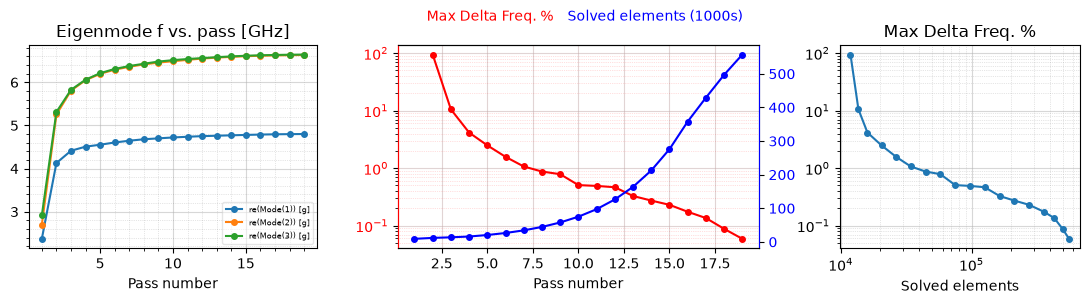

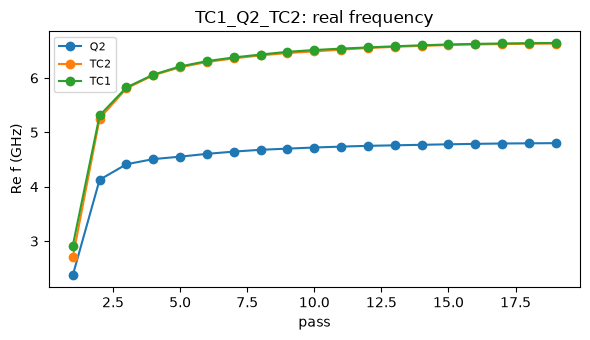

INFO 05:03PM [analyze_variation]: Variation 0
INFO 05:03PM [make_dispersive]: Starting diagonalization (512×512 matrix)
INFO 05:03PM [make_dispersive]: Diagonalization complete



TC1_Q2_TC2: modes (numerical diagonalisation)
     f (GHz)  target (GHz)  |anharmonicity| (MHz)  max junction participation
Q2    4.6594          4.55               146.6350                      0.9827
TC2   6.4944          6.35               132.4542                      0.4948
TC1   6.5049          6.35                 9.7058                      0.4926

Cross-Kerr shifts (MHz): one excitation in the row's mode shifts the
column's mode down by this much. Diagonal: the mode's own |anharmonicity|.
NaN: the two modes were not diagonalised together.
          Q2      TC2      TC1
Q2   146.635    0.405    1.754
TC2    0.405  132.454  142.177
TC1    1.754  142.177    9.706
(saved to hfss_results/qubits_couplers/TC1_Q2_TC2_*.csv)

TC2_Q3_TC3: mirror image of TC0_Q1_TC1, not simulated
     f (GHz)  target (GHz)  |anharmonicity| (MHz)  max junction participation
Q3    4.9014          4.80               163.0134                      0.9814
TC2   6.5117          6.35               142.4200    

In [13]:
# Coupler-qubit-coupler: each inner qubit in hfss_epr_qubits with the
# couplers on either side (and their control lines). Three modes, diagonalised
# together. The qubit sees both of its couplers here, as in the full chip.
# With hfss_use_mirror_symmetry, Q3 is Q1 relabelled.
if run_hfss_qubit_epr:
    rows = {}
    for q in hfss_epr_qubits:
        r = get_run([q], [q - 1, q])
        rows[f"Q{q}" + (" (mirror)" if "mirror_of" in r else "")] = qubit_summary_row(r, q)
    qubit_summary = pd.DataFrame(rows).T
    qubit_summary.to_csv(os.path.join(hfss_results_dir, "qubit_summary.csv"))
    print("\nInner qubits (TCa = the lower-numbered coupler), each from its own run:")
    print(qubit_summary.round(3).to_string())


In [14]:
# The whole array: every qubit and coupler (and their control lines) in one
# eigenmode simulation, 9 modes. Off by default: it crashed AEDT here. Each coupler is diagonalised with its two
# qubits (see run_epr), so the ZZ is computed between neighbours only.
if run_hfss_array_epr:
    r = run_epr("array", list(range(n_qubits)), list(range(n_qubits - 1)))
    hfss_results["array"] = r
    modes, chi = r["modes"], r["chi"]
    array_elements = pd.DataFrame(
        {
            name: {
                "f (GHz)": modes.loc[name, "f (GHz)"],
                "target (GHz)": squids[name]["freq_ghz"],
                "|anharmonicity| (MHz)": chi.loc[name, name],
                "target |anharm.| (MHz)": -squids[name]["alpha_mhz"],
                **({"T1 limit (us)": modes.loc[name, "T1 limit (us)"]}
                   if "T1 limit (us)" in modes else {}),
            }
            for name in squids
        }
    ).T
    array_couplers = pd.DataFrame(
        {f"TC{c}": coupler_summary_row(r, c) for c in range(n_qubits - 1)}
    ).T
    array_elements.to_csv(os.path.join(hfss_results_dir, "array_elements.csv"))
    array_couplers.to_csv(os.path.join(hfss_results_dir, "array_couplers.csv"))
    print("\nArray, qubits and couplers (T1 limit: from the control lines alone):")
    print(array_elements.round(4).to_string())
    print("\nArray, couplers (Qa = the lower-numbered qubit):")
    print(array_couplers.round(3).to_string())

In [15]:
# Every element against each run it was in: frequency, |anharmonicity| and
# T1 limit from its control lines. Inner elements appear in two or three runs;
# the spread between them is what the missing neighbours change.
if hfss_on and hfss_results:
    long = []
    for run, r in hfss_results.items():
        for name in squids:
            if name in r["modes"].index:
                row = {"element": name, "run": run,
                       "f (GHz)": r["modes"].loc[name, "f (GHz)"],
                       "|anharm.| (MHz)": r["chi"].loc[name, name]}
                if "T1 limit (us)" in r["modes"]:
                    row["T1 limit (us)"] = r["modes"].loc[name, "T1 limit (us)"]
                long.append(row)
    long = pd.DataFrame(long)
    long.to_csv(os.path.join(hfss_results_dir, "elements_by_run.csv"), index=False)
    order = [n for n in squids if n in set(long["element"])]
    for quantity in [c for c in ("f (GHz)", "|anharm.| (MHz)", "T1 limit (us)") if c in long]:
        table = long.pivot(index="element", columns="run", values=quantity).loc[order]
        if quantity == "f (GHz)":
            table.insert(0, "target", [squids[n]["freq_ghz"] for n in order])
        print(f"\n{quantity}, by run:")
        print(table.round(4).to_string(na_rep=""))



f (GHz), by run:
run      target  Q0_TC0_Q1  Q1_TC1_Q2  Q2_TC2_Q3 (mirror)  Q3_TC3_Q4 (mirror)  TC0_Q1_TC1  TC1_Q2_TC2  TC2_Q3_TC3 (mirror)
element                                                                                                                   
Q0         5.05     5.1387                                                                                                
Q1         4.80     4.9066     4.8976                                              4.9014                                 
Q2         4.55                4.6606              4.6606                                      4.6594                     
Q3         4.80                                    4.8976              4.9066                                       4.9014
Q4         5.05                                                        5.1387                                             
TC0        6.60     6.7540                                                         6.7352                                

In [16]:
# Save the AEDT project (every simulation above is a design in it) and
# release the connection to AEDT. AEDT itself stays open for inspection.
if hfss_on:
    hfss.pinfo.project.save()
    print(f"Saved the HFSS project to {hfss_project_path}")
    hfss.stop()

Saved the HFSS project to c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\qubits_couplers_hfss.aedt
Warning! 6 COM references still alive
Ansys will likely refuse to shut down
